<a href="https://colab.research.google.com/github/HsiangTNA/CS5785-AML-Kaggle-Challenge/blob/main/Code/Human_or_AI_Text_Authorship_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Human or AI? Text Authorship Classification


## 1. Environment Setup and Configuration


### 1.1 Install and Import Dependencies


In [1]:
import sys
import json
import random
import zipfile
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Dependencies imported successfully.")

Python: 3.13.18
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Dependencies imported successfully.


### 1.2 Configure Data and Output Paths


In [2]:
from pathlib import Path

# Detect Google Colab.
try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

REQUIRED_FILES = [
    "train.csv",
    "test.csv",
    "unlabeled.csv",
    "train_starter_2000.csv",
    "sample_submission.csv",
]

if IN_COLAB:
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/human_or_ai")
    DATA_DIR = PROJECT_DIR / "data"
else:
    # Find Data/ or data/ from the current directory or its parents.
    current_dir = Path.cwd()
    DATA_DIR = next(
        (
            folder / directory_name
            for folder in [current_dir, *current_dir.parents]
            for directory_name in ["Data", "data"]
            if (folder / directory_name).is_dir()
        ),
        None,
    )

    if DATA_DIR is None:
        raise FileNotFoundError(
            f"Cannot find a Data/ or data/ folder in "
            f"{current_dir} or its parents."
        )

    PROJECT_DIR = DATA_DIR.parent

OUTPUT_DIR = PROJECT_DIR / "outputs"

print("Environment:", "Google Colab" if IN_COLAB else "Local")
print("Data folder:", DATA_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

# Check that all required files exist.
missing = [
    name for name in REQUIRED_FILES
    if not (DATA_DIR / name).is_file()
]
if missing:
    raise FileNotFoundError(
        f"Missing files in {DATA_DIR.resolve()}:\n"
        + "\n".join(f"  - {name}" for name in missing)
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
UNLABELED_PATH = DATA_DIR / "unlabeled.csv"
STARTER_PATH = DATA_DIR / "train_starter_2000.csv"
SAMPLE_SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

for name in REQUIRED_FILES:
    size_mb = (DATA_DIR / name).stat().st_size / 1_000_000
    print(f"  {name}: {size_mb:.3f} MB")

print("All five competition files are ready.")

Mounted at /content/drive
Environment: Google Colab
Data folder: /content/drive/MyDrive/human_or_ai/data
Output folder: /content/drive/MyDrive/human_or_ai/outputs
  train.csv: 12.749 MB
  test.csv: 3.866 MB
  unlabeled.csv: 3.842 MB
  train_starter_2000.csv: 2.568 MB
  sample_submission.csv: 0.030 MB
All five competition files are ready.


### 1.3 Set Random Seeds and Experiment Parameters


In [3]:
import sys
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

# Ensure the output folder exists on both Colab and local machines.
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reproducible experiment settings.
SEED = 42
VALIDATION_SIZE = 2000
TRAINING_SIZES = [500, 1000, 2000, 5000, 8000]
DECISION_THRESHOLD = 0.5

random.seed(SEED)
np.random.seed(SEED)

# Also pass random_state=SEED to splits and estimators that support it.
CONFIG = {
    "seed": SEED,
    "validation_size": VALIDATION_SIZE,
    "training_sizes": TRAINING_SIZES,
    "decision_threshold": DECISION_THRESHOLD,
    "metric": "roc_auc",
    "label_mapping": {"human": 0, "ai": 1},
    "data_dir": str(Path(DATA_DIR).resolve()),
    "output_dir": str(OUTPUT_DIR.resolve()),
}

VERSIONS = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
}

CONFIG_PATH = OUTPUT_DIR / "config.json"
ENVIRONMENT_PATH = OUTPUT_DIR / "environment.json"

CONFIG_PATH.write_text(
    json.dumps(CONFIG, indent=2),
    encoding="utf-8",
)
ENVIRONMENT_PATH.write_text(
    json.dumps(VERSIONS, indent=2),
    encoding="utf-8",
)

print("Experiment configuration:")
print(json.dumps(CONFIG, indent=2))

print("\nPackage versions:")
print(json.dumps(VERSIONS, indent=2))

print("\nSaved files:")
print(CONFIG_PATH.resolve())
print(ENVIRONMENT_PATH.resolve())

Experiment configuration:
{
  "seed": 42,
  "validation_size": 2000,
  "training_sizes": [
    500,
    1000,
    2000,
    5000,
    8000
  ],
  "decision_threshold": 0.5,
  "metric": "roc_auc",
  "label_mapping": {
    "human": 0,
    "ai": 1
  },
  "data_dir": "/content/drive/MyDrive/human_or_ai/data",
  "output_dir": "/content/drive/MyDrive/human_or_ai/outputs"
}

Package versions:
{
  "python": "3.13.18",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scikit_learn": "1.6.1"
}

Saved files:
/content/drive/MyDrive/human_or_ai/outputs/config.json
/content/drive/MyDrive/human_or_ai/outputs/environment.json


## 2. Data Loading and Exploration


### 2.1 Load the Datasets


In [4]:
import pandas as pd
from IPython.display import display

# Read each CSV once and keep the dataframes for later sections.
datasets = {
    filename: pd.read_csv(DATA_DIR / filename)
    for filename in REQUIRED_FILES
}

train_df = datasets["train.csv"]
test_df = datasets["test.csv"]
unlabeled_df = datasets["unlabeled.csv"]
starter_df = datasets["train_starter_2000.csv"]
sample_submission_df = datasets["sample_submission.csv"]

dataset_summary = pd.DataFrame([
    {
        "Dataset": filename,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Headers": ", ".join(df.columns),
        "File size (MB)": (DATA_DIR / filename).stat().st_size / 1_000_000,
    }
    for filename, df in datasets.items()
])

display(dataset_summary.style.format({
    "Rows": "{:,}",
    "Columns": "{:d}",
    "File size (MB)": "{:.3f}",
}).hide(axis="index"))

print("Row counts exclude the header. 1 MB = 1,000,000 bytes.")
print("train_starter_2000.csv is a subset of train.csv; do not combine them as extra training data.")


Dataset,Rows,Columns,Headers,File size (MB)
train.csv,"10,000",3,"id, text, label",12.749
test.csv,"3,000",2,"id, text",3.866
unlabeled.csv,"3,000",2,"id, text",3.842
train_starter_2000.csv,"2,000",3,"id, text, label",2.568
sample_submission.csv,"3,000",2,"id, label",0.030


Row counts exclude the header. 1 MB = 1,000,000 bytes.
train_starter_2000.csv is a subset of train.csv; do not combine them as extra training data.


### 2.2 Inspect Data Structure and Class Distribution


,Dataset,Column,Data type,Non-null rows
0,train.csv,id,int64,10000
1,train.csv,text,object,10000
2,train.csv,label,int64,10000
3,test.csv,id,int64,3000
4,test.csv,text,object,3000
5,unlabeled.csv,id,int64,3000
6,unlabeled.csv,text,object,3000
7,train_starter_2000.csv,id,int64,2000
8,train_starter_2000.csv,text,object,2000
9,train_starter_2000.csv,label,int64,2000


,Dataset,Label,Class,Rows,Share (%)
0,train.csv,0,Human,5000,50.0
1,train.csv,1,AI,5000,50.0
2,train_starter_2000.csv,0,Human,1000,50.0
3,train_starter_2000.csv,1,AI,1000,50.0


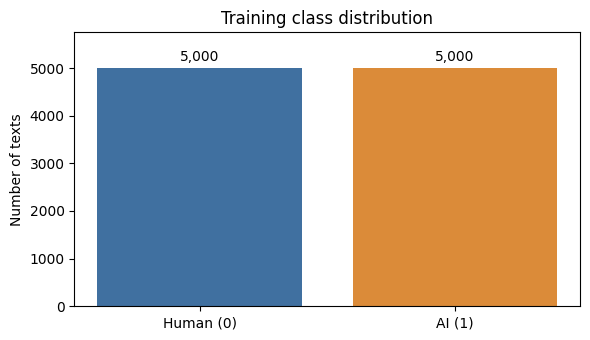

Human = 0; AI = 1. Test and unlabeled data have no ground-truth labels.
The 0.5 values in sample_submission.csv are placeholders, not class labels.


In [5]:
# Inspect the original columns without modifying any source dataframe.
expected_columns = {
    "train.csv": ["id", "text", "label"],
    "test.csv": ["id", "text"],
    "unlabeled.csv": ["id", "text"],
    "train_starter_2000.csv": ["id", "text", "label"],
    "sample_submission.csv": ["id", "label"],
}
for filename, expected in expected_columns.items():
    assert datasets[filename].columns.tolist() == expected, filename

schema_summary = pd.DataFrame([
    {"Dataset": filename, "Column": column,
     "Data type": str(df[column].dtype), "Non-null rows": int(df[column].notna().sum())}
    for filename, df in datasets.items() for column in df.columns
])
display(schema_summary)

LABEL_NAMES = {0: "Human", 1: "AI"}
class_rows = []
for filename in ["train.csv", "train_starter_2000.csv"]:
    labels = datasets[filename]["label"]
    assert labels.notna().all() and labels.isin([0, 1]).all(), filename
    for label, count in labels.value_counts().sort_index().items():
        class_rows.append({"Dataset": filename, "Label": label,
                           "Class": LABEL_NAMES[label], "Rows": count,
                           "Share (%)": 100 * count / len(labels)})
class_distribution = pd.DataFrame(class_rows)
display(class_distribution)

fig, ax = plt.subplots(figsize=(6, 3.5))
counts = train_df["label"].value_counts().reindex([0, 1], fill_value=0)
bars = ax.bar(["Human (0)", "AI (1)"], counts, color=["#4070A0", "#DB8B39"])
ax.bar_label(bars, labels=[f"{n:,}" for n in counts], padding=3)
ax.set(title="Training class distribution", ylabel="Number of texts", ylim=(0, counts.max() * 1.15))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

schema_summary.to_csv(OUTPUT_DIR / "dataset_schema.csv", index=False)
class_distribution.to_csv(OUTPUT_DIR / "class_distribution.csv", index=False)
print("Human = 0; AI = 1. Test and unlabeled data have no ground-truth labels.")
print("The 0.5 values in sample_submission.csv are placeholders, not class labels.")


### 2.3 Check Missing Values and Duplicate Texts


In [6]:
# Normalization is only for duplicate checks; original text stays unchanged.
def normalize_for_audit(text):
    return text.astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.lower()

missing_summary = pd.DataFrame([
    {"Dataset": name, "Column": column, "Missing": int(df[column].isna().sum())}
    for name, df in datasets.items() for column in df.columns
])
audit_rows = []
for name, df in datasets.items():
    row = {"Dataset": name, "Missing cells": int(df.isna().sum().sum()),
           "Duplicate rows": int(df.duplicated().sum()),
           "Duplicate IDs": int(df["id"].duplicated().sum()),
           "Blank texts": pd.NA, "Duplicate texts": pd.NA,
           "Normalized duplicate texts": pd.NA}
    if "text" in df:
        text = df["text"].dropna()
        row.update({"Blank texts": int(text.str.strip().eq("").sum()),
                    "Duplicate texts": int(text.duplicated().sum()),
                    "Normalized duplicate texts": int(normalize_for_audit(text).duplicated().sum())})
    audit_rows.append(row)
quality_summary = pd.DataFrame(audit_rows)
display(missing_summary)
display(quality_summary.fillna("N/A"))
print("Duplicate counts are extra occurrences after the first; N/A means there is no text column.")

pairs = [("train.csv", "test.csv"), ("train.csv", "unlabeled.csv"),
         ("test.csv", "unlabeled.csv"), ("train.csv", "train_starter_2000.csv")]
overlap_rows = []
for left, right in pairs:
    a, b = datasets[left], datasets[right]
    overlap_rows.append({"Left dataset": left, "Right dataset": right,
        "Shared IDs": len(set(a["id"]) & set(b["id"])),
        "Shared normalized texts": len(set(normalize_for_audit(a["text"]).dropna()) &
                                       set(normalize_for_audit(b["text"]).dropna()))})
overlap_summary = pd.DataFrame(overlap_rows)
display(overlap_summary)

assert quality_summary["Missing cells"].eq(0).all(), "Review missing data before modeling."
assert quality_summary["Duplicate IDs"].eq(0).all(), "Review duplicate IDs before splitting."
assert quality_summary["Blank texts"].dropna().eq(0).all(), "Review blank text before modeling."
assert sample_submission_df["id"].equals(test_df["id"]), "Submission IDs/order differ from test."
starter_match = starter_df.merge(train_df, on=["id", "text", "label"], validate="one_to_one")
assert len(starter_match) == len(starter_df), "Starter data is not an exact training subset."

missing_summary.to_csv(OUTPUT_DIR / "missing_values.csv", index=False)
quality_summary.to_csv(OUTPUT_DIR / "data_quality.csv", index=False)
overlap_summary.to_csv(OUTPUT_DIR / "dataset_overlap.csv", index=False)
print("Data integrity checks passed. No rows were removed or changed.")
print("Starter overlap is expected: all 2,000 starter rows already belong to train.csv.")
print("This audit detects exact and case/whitespace-normalized matches, not semantic near-duplicates.")


,Dataset,Column,Missing
0,train.csv,id,0
1,train.csv,text,0
2,train.csv,label,0
3,test.csv,id,0
4,test.csv,text,0
5,unlabeled.csv,id,0
6,unlabeled.csv,text,0
7,train_starter_2000.csv,id,0
8,train_starter_2000.csv,text,0
9,train_starter_2000.csv,label,0


,Dataset,Missing cells,Duplicate rows,Duplicate IDs,Blank texts,Duplicate texts,Normalized duplicate texts
0,train.csv,0,0,0,0,0,0
1,test.csv,0,0,0,0,0,0
2,unlabeled.csv,0,0,0,0,0,0
3,train_starter_2000.csv,0,0,0,0,0,0
4,sample_submission.csv,0,0,0,N/A,N/A,N/A


Duplicate counts are extra occurrences after the first; N/A means there is no text column.


,Left dataset,Right dataset,Shared IDs,Shared normalized texts
0,train.csv,test.csv,0,0
1,train.csv,unlabeled.csv,0,0
2,test.csv,unlabeled.csv,0,0
3,train.csv,train_starter_2000.csv,2000,2000


Data integrity checks passed. No rows were removed or changed.
Starter overlap is expected: all 2,000 starter rows already belong to train.csv.
This audit detects exact and case/whitespace-normalized matches, not semantic near-duplicates.


### 2.4 Explore Text Length Distributions


,Dataset,Rows,Mean_words,Median_words,Min_words,P90_words,P95_words,Max_words,Mean_characters,Median_characters,Min_characters,Max_characters
0,train.csv,10000,208.7,206.0,75,295.0,316.0,350,1260.9,1246.0,331,2938
1,test.csv,3000,217.0,213.0,75,301.0,323.0,350,1274.9,1247.0,365,2631
2,unlabeled.csv,3000,210.3,206.5,75,303.1,324.0,350,1268.1,1260.0,363,2608
3,train_starter_2000.csv,2000,209.9,207.0,76,297.1,318.0,349,1269.3,1250.0,361,2607


,Class,Rows,Mean_words,Median_words,Mean_characters,Median_characters
0,AI,5000,208.4,209.0,1282.8,1278.0
1,Human,5000,209.0,204.0,1239.0,1222.0


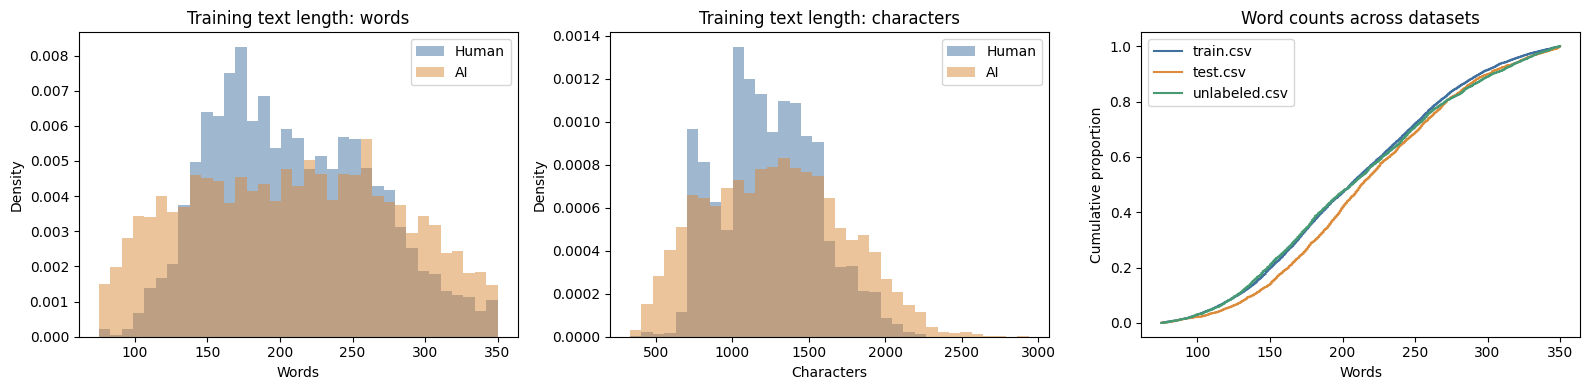

sample_submission.csv has no text, so it is excluded from length analysis.
The starter subset is reported in the table but excluded from the cross-dataset plot.
These are descriptive summaries. Similar lengths alone do not establish similar writing styles.
Any learned preprocessing or later length-bin cutoffs must use only the training split.


In [7]:
# Words = whitespace-separated tokens; characters include spaces/punctuation.
# Keep these descriptive features separate from the original model inputs.
length_frames = []
for name, df in datasets.items():
    if "text" not in df:
        continue
    lengths = pd.DataFrame({"Dataset": name, "id": df["id"],
        "words": df["text"].str.count(r"\S+"),
        "characters": df["text"].str.len()})
    lengths["Class"] = df["label"].map(LABEL_NAMES) if "label" in df else "Unknown"
    length_frames.append(lengths)
length_data = pd.concat(length_frames, ignore_index=True)

length_summary = length_data.groupby("Dataset", sort=False).agg(
    Rows=("id", "size"), Mean_words=("words", "mean"),
    Median_words=("words", "median"), Min_words=("words", "min"),
    P90_words=("words", lambda x: x.quantile(0.90)),
    P95_words=("words", lambda x: x.quantile(0.95)), Max_words=("words", "max"),
    Mean_characters=("characters", "mean"), Median_characters=("characters", "median"),
    Min_characters=("characters", "min"), Max_characters=("characters", "max")
).reset_index()
display(length_summary.round(1))
train_lengths = length_data[length_data["Dataset"].eq("train.csv")]
class_length_summary = train_lengths.groupby("Class").agg(
    Rows=("id", "size"), Mean_words=("words", "mean"), Median_words=("words", "median"),
    Mean_characters=("characters", "mean"), Median_characters=("characters", "median")
).reset_index()
display(class_length_summary.round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for feature, ax in zip(["words", "characters"], axes[:2]):
    bins = np.histogram_bin_edges(train_lengths[feature], bins=35)
    for label, color in [("Human", "#4070A0"), ("AI", "#DB8B39")]:
        values = train_lengths.loc[train_lengths["Class"].eq(label), feature]
        ax.hist(values, bins=bins, density=True, alpha=0.5, label=label, color=color)
    ax.set(title=f"Training text length: {feature}", xlabel=feature.capitalize(), ylabel="Density")
    ax.legend()
for name, color in [("train.csv", "#4070A0"), ("test.csv", "#DB8B39"), ("unlabeled.csv", "#469A74")]:
    values = np.sort(length_data.loc[length_data["Dataset"].eq(name), "words"].to_numpy())
    axes[2].step(values, np.arange(1, len(values) + 1) / len(values),
                 where="post", label=name, color=color)
axes[2].set(title="Word counts across datasets", xlabel="Words", ylabel="Cumulative proportion")
axes[2].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "text_length_distributions.png", dpi=160, bbox_inches="tight")
plt.show()
length_summary.to_csv(OUTPUT_DIR / "text_length_summary.csv", index=False)
class_length_summary.to_csv(OUTPUT_DIR / "class_length_summary.csv", index=False)
print("sample_submission.csv has no text, so it is excluded from length analysis.")
print("The starter subset is reported in the table but excluded from the cross-dataset plot.")
print("These are descriptive summaries. Similar lengths alone do not establish similar writing styles.")
print("Any learned preprocessing or later length-bin cutoffs must use only the training split.")


### 2.5 Create a Fixed Stratified Training–Validation Split


In [8]:
import hashlib

# Freeze a single stratified split for every later experiment.
assert len(train_df) == 10000 and VALIDATION_SIZE == 2000
assert train_df["id"].is_unique and train_df["id"].notna().all()
SPLIT_PATH = OUTPUT_DIR / "split_assignments.csv"
SPLIT_META_PATH = OUTPUT_DIR / "split_metadata.json"
expected_metadata = {
    "seed": SEED, "validation_size": VALIDATION_SIZE,
    "train_csv_sha256": hashlib.sha256(TRAIN_PATH.read_bytes()).hexdigest(),
}
assert SPLIT_PATH.exists() == SPLIT_META_PATH.exists(), "Incomplete saved split; review output files."
reuse_split = SPLIT_PATH.exists()
if reuse_split:
    split_metadata = json.loads(SPLIT_META_PATH.read_text())
    assert all(split_metadata.get(k) == v for k, v in expected_metadata.items()), (
        "Data or split settings changed. Keep the existing split intact and review the mismatch."
    )
    split_assignments = pd.read_csv(SPLIT_PATH, dtype={"id": train_df["id"].dtype})
else:
    train_ids, val_ids = train_test_split(
        train_df["id"].to_numpy(), test_size=VALIDATION_SIZE,
        stratify=train_df["label"].to_numpy(), random_state=SEED,
    )
    split_assignments = pd.concat([
        pd.DataFrame({"id": train_ids, "split": "train"}),
        pd.DataFrame({"id": val_ids, "split": "validation"}),
    ], ignore_index=True)

assert split_assignments.columns.tolist() == ["id", "split"]
assert split_assignments["id"].is_unique and len(split_assignments) == len(train_df)
assert set(split_assignments["id"]) == set(train_df["id"])
assert set(split_assignments["split"]) == {"train", "validation"}
train_ids = split_assignments.loc[split_assignments["split"].eq("train"), "id"].to_numpy()
val_ids = split_assignments.loc[split_assignments["split"].eq("validation"), "id"].to_numpy()
indexed_train = train_df.set_index("id", drop=False)
train_split = indexed_train.loc[train_ids].reset_index(drop=True).copy()
val_split = indexed_train.loc[val_ids].reset_index(drop=True).copy()

assert len(train_split) == 8000 and len(val_split) == 2000
assert not (set(train_ids) & set(val_ids))
assert train_split["label"].value_counts().to_dict() == {0: 4000, 1: 4000}
assert val_split["label"].value_counts().to_dict() == {0: 1000, 1: 1000}
shared_texts = set(normalize_for_audit(train_split["text"])) & set(normalize_for_audit(val_split["text"]))
assert not shared_texts, "Duplicate text crosses the split; review before training."
assert max(TRAINING_SIZES) <= len(train_split)

if not reuse_split:
    split_assignments.to_csv(SPLIT_PATH, index=False)
    SPLIT_META_PATH.write_text(json.dumps({**expected_metadata,
        "sklearn_version": sklearn.__version__, "method": "stratified train_test_split"}, indent=2))

X_train, y_train = train_split["text"].copy(), train_split["label"].copy()
X_val, y_val = val_split["text"].copy(), val_split["label"].copy()
split_summary = pd.DataFrame([
    {"Split": name, "Rows": len(df), "Human (0)": int(df["label"].eq(0).sum()),
     "AI (1)": int(df["label"].eq(1).sum()), "AI share (%)": 100 * df["label"].mean()}
    for name, df in [("Train", train_split), ("Validation", val_split)]
])
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)
print("Reused the saved split." if reuse_split else "Created and saved the fixed split.")
print("ID overlap: 0; normalized-text overlap: 0.")
print("Split assignments:", SPLIT_PATH)
print("Fit vectorizers and other learned preprocessing on X_train only.")
print("Keep X_val/y_val fixed for all experiments; do not train or pseudo-label with validation rows.")
print("Test/unlabeled rows and the starter subset were not added to this split.")


,Split,Rows,Human (0),AI (1),AI share (%)
0,Train,8000,4000,4000,50.0
1,Validation,2000,1000,1000,50.0


Reused the saved split.
ID overlap: 0; normalized-text overlap: 0.
Split assignments: /content/drive/MyDrive/human_or_ai/outputs/split_assignments.csv
Fit vectorizers and other learned preprocessing on X_train only.
Keep X_val/y_val fixed for all experiments; do not train or pseudo-label with validation rows.
Test/unlabeled rows and the starter subset were not added to this split.


## 3. Baseline Model


### 3.1 Text Preprocessing


In [9]:
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Validate the fixed split before training.
for name, texts, labels in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
]:
    assert len(texts) == len(labels), f"{name}: length mismatch."
    assert texts.notna().all(), f"{name}: missing text."
    assert texts.map(lambda value: isinstance(value, str)).all()
    assert texts.str.strip().ne("").all(), f"{name}: blank text."
    assert labels.isin([0, 1]).all(), f"{name}: invalid labels."

assert set(train_split["id"]).isdisjoint(set(val_split["id"]))

# Keep the original text. TF-IDF handles lowercasing and tokenization;
# this baseline does not remove stop words or apply stemming.
print(f"Training samples: {len(X_train):,}")
print(f"Validation samples: {len(X_val):,}")
print("Text validation completed; original texts preserved.")

Training samples: 8,000
Validation samples: 2,000
Text validation completed; original texts preserved.


### 3.2 TF-IDF Feature Extraction


In [10]:
TFIDF_CONFIG = {
    "lowercase": True,
    "strip_accents": None,
    "stop_words": None,
    "ngram_range": (1, 2),     # Use individual words and two-word phrases.
    "min_df": 2,              # Ignore terms appearing in only one training text.
    "max_df": 1.0,
    "max_features": 50_000,   # Limit vocabulary size to control memory usage.
    "sublinear_tf": True,     # Reduce the influence of repeated terms.
    "norm": "l2",
}

baseline_vectorizer = TfidfVectorizer(
    **TFIDF_CONFIG,
    dtype=np.float32,
)

# Learn the vocabulary and IDF weights from training data only.
start = perf_counter()
X_train_tfidf = baseline_vectorizer.fit_transform(X_train)
tfidf_fit_seconds = perf_counter() - start

# Reuse the fitted vectorizer to avoid validation-data leakage.
start = perf_counter()
X_val_tfidf = baseline_vectorizer.transform(X_val)
tfidf_val_transform_seconds = perf_counter() - start

feature_summary = pd.DataFrame([
    {
        "Split": name,
        "Rows": matrix.shape[0],
        "Features": matrix.shape[1],
        "Nonzero values": matrix.nnz,
        "Density (%)": (
            100 * matrix.nnz / (matrix.shape[0] * matrix.shape[1])
        ),
    }
    for name, matrix in [
        ("Train", X_train_tfidf),
        ("Validation", X_val_tfidf),
    ]
])

display(feature_summary.round(4))
print(f"Training TF-IDF fit/transform: {tfidf_fit_seconds:.2f} seconds")
print(f"Validation transform: {tfidf_val_transform_seconds:.2f} seconds")

,Split,Rows,Features,Nonzero values,Density (%)
0,Train,8000,50000,1588540,0.3971
1,Validation,2000,50000,387127,0.3871


Training TF-IDF fit/transform: 6.77 seconds
Validation transform: 1.21 seconds


### 3.3 Train a Logistic Regression Baseline


In [11]:
LR_CONFIG = {
    "C": 1.0,                 # Inverse regularization strength.
    "solver": "liblinear",
    "max_iter": 1000,
    "random_state": SEED,
}

baseline_classifier = LogisticRegression(**LR_CONFIG)

start = perf_counter()
baseline_classifier.fit(X_train_tfidf, y_train)
classifier_fit_seconds = perf_counter() - start

# Include feature extraction when reporting total training time.
baseline_fit_seconds = (
    tfidf_fit_seconds + classifier_fit_seconds
)

# Package the already-fitted components for prediction from raw text.
# Constructing this pipeline does not fit either component again.
baseline_model = Pipeline([
    ("tfidf", baseline_vectorizer),
    ("classifier", baseline_classifier),
])

print("Baseline training completed.")
print(f"Classifier fit time: {classifier_fit_seconds:.2f} seconds")
print(f"Total training time including TF-IDF: {baseline_fit_seconds:.2f} seconds")
print("Classes:", baseline_model.classes_)
print("Solver iterations:", baseline_classifier.n_iter_)

if baseline_classifier.n_iter_.max() >= LR_CONFIG["max_iter"]:
    print(
        "Warning: iteration limit reached; "
        "check convergence before comparing results."
    )

Baseline training completed.
Classifier fit time: 0.72 seconds
Total training time including TF-IDF: 7.49 seconds
Classes: [0 1]
Solver iterations: [5]


### 3.4 Define Reusable Evaluation Functions


In [12]:
def evaluate_binary_classifier(
    model,
    texts,
    labels,
    threshold=0.5,
):
    """Evaluate a fitted binary text classifier using AI probabilities."""
    if not 0 <= threshold <= 1:
        raise ValueError("threshold must be between 0 and 1.")

    labels = np.asarray(labels)
    classes = np.asarray(model.classes_)

    if len(classes) != 2 or set(classes.tolist()) != {0, 1}:
        raise ValueError("Expected binary classes 0 (human) and 1 (AI).")

    if set(np.unique(labels).tolist()) != {0, 1}:
        raise ValueError("Evaluation labels must contain both classes.")

    # Locate the AI class explicitly instead of assuming column order.
    ai_column = int(np.flatnonzero(classes == 1)[0])

    # Pipeline prediction time includes text vectorization.
    start = perf_counter()
    probabilities = model.predict_proba(texts)[:, ai_column]
    prediction_seconds = perf_counter() - start

    if len(probabilities) != len(labels):
        raise ValueError("Prediction and label lengths differ.")

    if (
        not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError("Invalid predicted probabilities.")

    predictions = (probabilities >= threshold).astype(int)

    # AUROC uses continuous probabilities; other metrics use the threshold.
    metrics = {
        "AUROC": roc_auc_score(labels, probabilities),
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "Recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "F1": f1_score(
            labels, predictions, zero_division=0
        ),
        "Prediction seconds": prediction_seconds,
    }

    return metrics, probabilities, predictions


print("Reusable evaluation function is ready.")

Reusable evaluation function is ready.


### 3.5 Evaluate and Record Baseline Performance


,Model,Split,AUROC,Accuracy,Precision,Recall,F1,Prediction seconds
0,TF-IDF + Logistic Regression,Train,0.9935,0.9534,0.9855,0.9202,0.9518,2.8781
1,TF-IDF + Logistic Regression,Validation,0.9361,0.8655,0.9075,0.8140,0.8582,0.7009


Training AUROC:   0.9935
Validation AUROC: 0.9361
Train minus validation AUROC: 0.0574


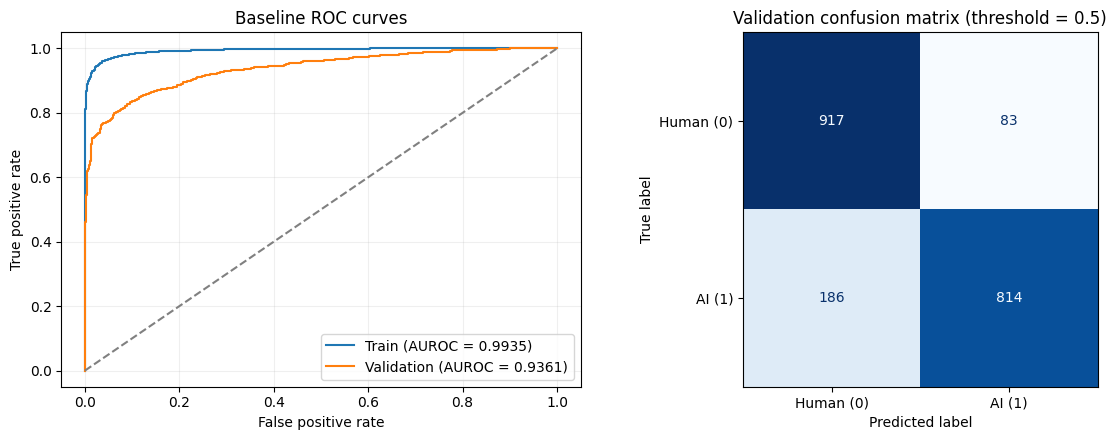

Baseline results saved to: /content/drive/MyDrive/human_or_ai/outputs/baseline


In [13]:
import json
import joblib

# Evaluate the same fitted model on training and held-out validation data.
train_metrics, train_prob_ai, train_predictions = (
    evaluate_binary_classifier(
        baseline_model,
        X_train,
        y_train,
        threshold=DECISION_THRESHOLD,
    )
)

val_metrics, val_prob_ai, val_predictions = (
    evaluate_binary_classifier(
        baseline_model,
        X_val,
        y_val,
        threshold=DECISION_THRESHOLD,
    )
)

baseline_results = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Split": "Train",
        **train_metrics,
    },
    {
        "Model": "TF-IDF + Logistic Regression",
        "Split": "Validation",
        **val_metrics,
    },
])

display(baseline_results.round(4))

# A large positive gap may indicate overfitting.
auc_gap = train_metrics["AUROC"] - val_metrics["AUROC"]
print(f"Training AUROC:   {train_metrics['AUROC']:.4f}")
print(f"Validation AUROC: {val_metrics['AUROC']:.4f}")
print(f"Train minus validation AUROC: {auc_gap:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Compare ranking performance across all classification thresholds.
for name, labels, probabilities, metrics in [
    ("Train", y_train, train_prob_ai, train_metrics),
    ("Validation", y_val, val_prob_ai, val_metrics),
]:
    fpr, tpr, _ = roc_curve(labels, probabilities)
    axes[0].plot(
        fpr,
        tpr,
        label=f"{name} (AUROC = {metrics['AUROC']:.4f})",
    )

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(
    title="Baseline ROC curves",
    xlabel="False positive rate",
    ylabel="True positive rate",
)
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.2)

# Show classification errors at the fixed decision threshold.
cm = confusion_matrix(y_val, val_predictions, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Human (0)", "AI (1)"],
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format="d",
)
axes[1].set_title(
    f"Validation confusion matrix (threshold = {DECISION_THRESHOLD})"
)

fig.tight_layout()

BASELINE_DIR = OUTPUT_DIR / "baseline"
BASELINE_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    BASELINE_DIR / "evaluation.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# Save metrics and feature statistics for later model comparisons.
baseline_results.to_csv(
    BASELINE_DIR / "metrics.csv",
    index=False,
)
feature_summary.to_csv(
    BASELINE_DIR / "feature_summary.csv",
    index=False,
)

# Preserve IDs so predictions can be joined with texts for error analysis.
validation_predictions = pd.DataFrame({
    "id": val_split["id"].to_numpy(),
    "label": np.asarray(y_val),
    "prob_ai": val_prob_ai,
    "pred_label": val_predictions,
})
validation_predictions.to_csv(
    BASELINE_DIR / "validation_predictions.csv",
    index=False,
)

# Save the complete fitted pipeline, including its vocabulary and IDF weights.
joblib.dump(
    baseline_model,
    BASELINE_DIR / "model.joblib",
)

# Record settings, timings, and split provenance for reproducibility.
baseline_metadata = {
    "model": "TF-IDF + Logistic Regression",
    "seed": SEED,
    "threshold": DECISION_THRESHOLD,
    "training_rows": len(X_train),
    "validation_rows": len(X_val),
    "features": X_train_tfidf.shape[1],
    "tfidf_config": TFIDF_CONFIG,
    "logistic_regression_config": LR_CONFIG,
    "tfidf_fit_seconds": tfidf_fit_seconds,
    "classifier_fit_seconds": classifier_fit_seconds,
    "total_fit_seconds": baseline_fit_seconds,
    "validation_transform_seconds": tfidf_val_transform_seconds,
    "train_minus_validation_auroc": auc_gap,
    "split_metadata": json.loads(SPLIT_META_PATH.read_text()),
    "versions": VERSIONS,
}

(BASELINE_DIR / "metadata.json").write_text(
    json.dumps(baseline_metadata, indent=2),
    encoding="utf-8",
)

print(f"Baseline results saved to: {BASELINE_DIR.resolve()}")

## 4. Model Comparison and Hyperparameter Tuning


### 4.1 Define Candidate Models


In [14]:
import json
import joblib
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Keep this experiment separate from earlier coarse-to-fine searches.
COMPARISON_DIR = OUTPUT_DIR / "model_comparison_5fold_5values"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

# All models use the same TF-IDF settings as the baseline.
COMPARISON_TFIDF_CONFIG = TFIDF_CONFIG.copy()

MODEL_SPECS = {
    "Logistic Regression": {
        "file_tag": "logistic_regression",
        "classifier": LogisticRegression(
            solver="liblinear",
            max_iter=5000,
            random_state=SEED,
        ),
        "param_grid": {
            "classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        },
    },
    "Multinomial Naive Bayes": {
        "file_tag": "multinomial_nb",
        "classifier": MultinomialNB(),
        "param_grid": {
            "classifier__alpha": [0.001, 0.01, 0.1, 1.0, 10.0],
        },
    },
    "Linear SVM": {
        "file_tag": "linear_svm",
        "classifier": LinearSVC(
            dual=True,
            max_iter=20_000,
            random_state=SEED,
        ),
        "param_grid": {
            "classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        },
    },
}


def make_candidate_pipeline(classifier):
    """Create a fresh pipeline for leakage-free cross-validation."""
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                **COMPARISON_TFIDF_CONFIG,
                dtype=np.float32,
            ),
        ),
        ("classifier", clone(classifier)),
    ])


for name, spec in MODEL_SPECS.items():
    print(f"{name}: {spec['param_grid']}")

Logistic Regression: {'classifier__C': [0.01, 0.1, 1.0, 10.0, 100.0]}
Multinomial Naive Bayes: {'classifier__alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}
Linear SVM: {'classifier__C': [0.01, 0.1, 1.0, 10.0, 100.0]}


### 4.2 Establish a Fair Comparison Protocol


In [15]:
CV_FOLDS = 5
N_JOBS = 2

# Preserve the fixed 8,000/2,000 split from Section 2.
assert len(X_train) == len(y_train) == 8000
assert len(X_val) == len(y_val) == 2000
assert set(train_split["id"]).isdisjoint(set(val_split["id"]))

# Verify that texts, labels, and IDs have matching row order.
assert np.array_equal(
    np.asarray(X_train), train_split["text"].to_numpy()
)
assert np.array_equal(
    np.asarray(y_train), train_split["label"].to_numpy()
)
assert np.array_equal(
    np.asarray(X_val), val_split["text"].to_numpy()
)
assert np.array_equal(
    np.asarray(y_val), val_split["label"].to_numpy()
)

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED,
)

# Reuse exactly the same folds for every model and parameter value.
cv_splits = list(cv.split(X_train, y_train))

fold_ids = np.full(len(X_train), -1, dtype=int)
holdout_counts = np.zeros(len(X_train), dtype=int)
fold_rows = []

for fold, (fit_indices, holdout_indices) in enumerate(cv_splits, start=1):
    fold_ids[holdout_indices] = fold
    holdout_counts[holdout_indices] += 1

    assert len(fit_indices) == 6400
    assert len(holdout_indices) == 1600
    assert np.intersect1d(fit_indices, holdout_indices).size == 0

    fold_rows.append({
        "Fold": fold,
        "Training rows": len(fit_indices),
        "Training AI share (%)": (
            100 * np.asarray(y_train)[fit_indices].mean()
        ),
        "CV holdout rows": len(holdout_indices),
        "CV holdout AI share (%)": (
            100 * np.asarray(y_train)[holdout_indices].mean()
        ),
    })

assert (holdout_counts == 1).all()

cv_fold_assignments = pd.DataFrame({
    "id": train_split["id"].to_numpy(),
    "cv_holdout_fold": fold_ids,
})
cv_fold_assignments.to_csv(
    COMPARISON_DIR / "cv_fold_assignments.csv",
    index=False,
)

display(pd.DataFrame(fold_rows))

print("Selection metric: mean 5-fold CV AUROC.")
print("Each fold: 6,400 training rows and 1,600 CV holdout rows.")
print("The fixed 2,000-row validation set is excluded from CV.")
print("Total: 75 CV fits plus 3 full-training refits.")

,Fold,Training rows,Training AI share (%),CV holdout rows,CV holdout AI share (%)
0,1,6400,50.0,1600,50.0
1,2,6400,50.0,1600,50.0
2,3,6400,50.0,1600,50.0
3,4,6400,50.0,1600,50.0
4,5,6400,50.0,1600,50.0


Selection metric: mean 5-fold CV AUROC.
Each fold: 6,400 training rows and 1,600 CV holdout rows.
The fixed 2,000-row validation set is excluded from CV.
Total: 75 CV fits plus 3 full-training refits.


### 4.3 Tune Hyperparameters for Logistic Regression & Linear SVM & Multiomial Naive Bayes Models



Tuning Logistic Regression...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best parameters: {'classifier__C': 10.0}
Best CV AUROC: 0.9419
Search time: 142.22 seconds

Tuning Multinomial Naive Bayes...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best parameters: {'classifier__alpha': 0.1}
Best CV AUROC: 0.8891
Search time: 127.14 seconds

Tuning Linear SVM...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best parameters: {'classifier__C': 1.0}
Best CV AUROC: 0.9417
Search time: 139.04 seconds


,Model,CV AUROC,CV AUROC std,Best parameters,Search seconds,Refit seconds
0,Logistic Regression,0.9419,0.0072,"{""classifier__C"": 10.0}",142.2193,8.1958
1,Linear SVM,0.9417,0.0071,"{""classifier__C"": 1.0}",139.0389,6.2653
2,Multinomial Naive Bayes,0.8891,0.0097,"{""classifier__alpha"": 0.1}",127.1402,5.9067


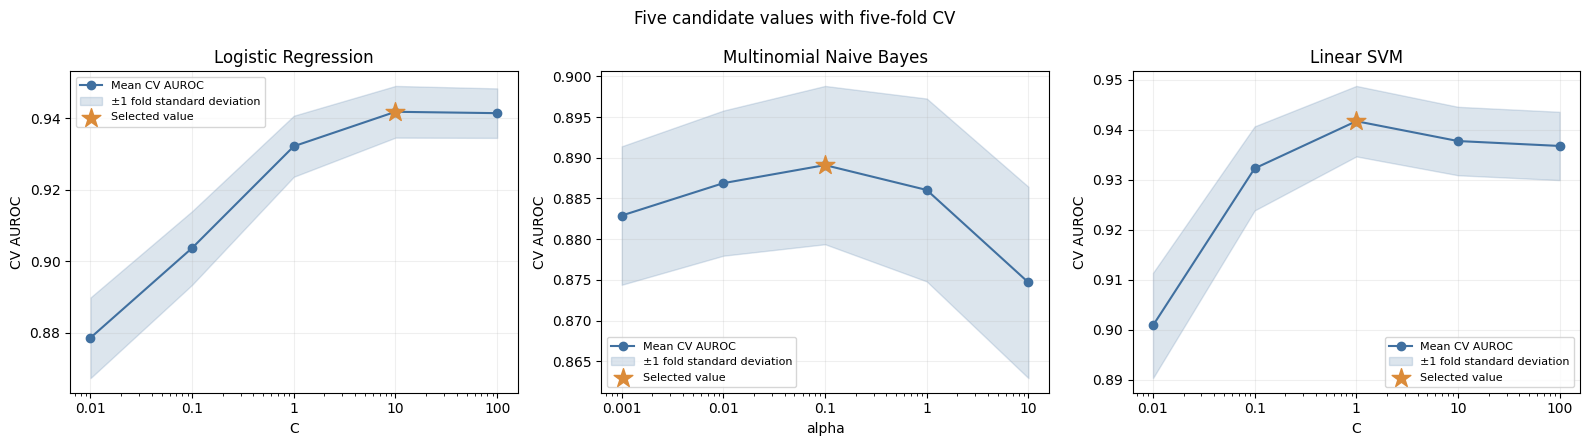

Shaded bands show fold variation, not confidence intervals.


In [16]:
searches = {}
search_rows = []

for name, spec in MODEL_SPECS.items():
    print(f"\nTuning {name}...", flush=True)

    search = GridSearchCV(
        estimator=make_candidate_pipeline(spec["classifier"]),
        param_grid=spec["param_grid"],
        scoring="roc_auc",
        cv=cv_splits,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        refit=True,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    # Use raw text so each fold learns its own vocabulary and IDF weights.
    start = perf_counter()
    search.fit(X_train, y_train)
    search_seconds = perf_counter() - start

    searches[name] = search
    best_index = search.best_index_

    search_rows.append({
        "Model": name,
        "CV AUROC": float(search.best_score_),
        "CV AUROC std": float(
            search.cv_results_["std_test_score"][best_index]
        ),
        "Best parameters": json.dumps(search.best_params_),
        "Search seconds": search_seconds,
        "Refit seconds": float(search.refit_time_),
    })

    # Save all candidate results and the best fitted pipeline.
    pd.DataFrame(search.cv_results_).to_csv(
        COMPARISON_DIR / f"{spec['file_tag']}_cv_results.csv",
        index=False,
    )
    joblib.dump(
        search.best_estimator_,
        COMPARISON_DIR / f"{spec['file_tag']}_model.joblib",
    )

    print("Best parameters:", search.best_params_)
    print(f"Best CV AUROC: {search.best_score_:.4f}")
    print(f"Search time: {search_seconds:.2f} seconds")

cv_summary = (
    pd.DataFrame(search_rows)
    .sort_values("CV AUROC", ascending=False, kind="stable")
    .reset_index(drop=True)
)

cv_summary.to_csv(
    COMPARISON_DIR / "cv_summary.csv",
    index=False,
)
display(cv_summary.round(4))

# Visualize the five candidate values for each model.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, search) in zip(axes, searches.items()):
    results = pd.DataFrame(search.cv_results_)
    param_name = next(iter(MODEL_SPECS[name]["param_grid"]))

    results["parameter_value"] = (
        results[f"param_{param_name}"].astype(float)
    )
    results = results.sort_values("parameter_value")

    x = results["parameter_value"].to_numpy()
    mean_auc = results["mean_test_score"].to_numpy()
    std_auc = results["std_test_score"].to_numpy()

    ax.plot(
        x, mean_auc,
        marker="o",
        color="#4070A0",
        label="Mean CV AUROC",
    )
    ax.fill_between(
        x,
        np.clip(mean_auc - std_auc, 0, 1),
        np.clip(mean_auc + std_auc, 0, 1),
        color="#4070A0",
        alpha=0.18,
        label="±1 fold standard deviation",
    )
    ax.scatter(
        float(search.best_params_[param_name]),
        search.best_score_,
        marker="*",
        s=200,
        color="#DB8B39",
        zorder=5,
        label="Selected value",
    )

    ax.set_xscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{value:g}" for value in x])
    ax.set(
        title=name,
        xlabel=param_name.replace("classifier__", ""),
        ylabel="CV AUROC",
    )
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle("Five candidate values with five-fold CV")
fig.tight_layout()
fig.savefig(
    COMPARISON_DIR / "hyperparameter_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Shaded bands show fold variation, not confidence intervals.")

### 4.4 Compare Training AUROC, Validation AUROC, and Runtime


,Model,CV AUROC,CV AUROC std,Train AUROC,Validation AUROC,AUROC gap
0,Logistic Regression,0.9419,0.0072,1.0000,0.9430,0.0570
1,Linear SVM,0.9417,0.0071,1.0000,0.9425,0.0575
2,Multinomial Naive Bayes,0.8891,0.0097,0.9877,0.8971,0.0906


,Model,Validation accuracy,Validation precision,Validation recall,Validation F1
0,Logistic Regression,0.8745,0.9049,0.837,0.8696
1,Linear SVM,0.8735,0.9047,0.835,0.8684
2,Multinomial Naive Bayes,0.8130,0.8330,0.783,0.8072


,Model,Search seconds,Refit seconds,Validation prediction seconds
0,Logistic Regression,142.219,8.196,0.718
1,Linear SVM,139.039,6.265,1.247
2,Multinomial Naive Bayes,127.140,5.907,0.724


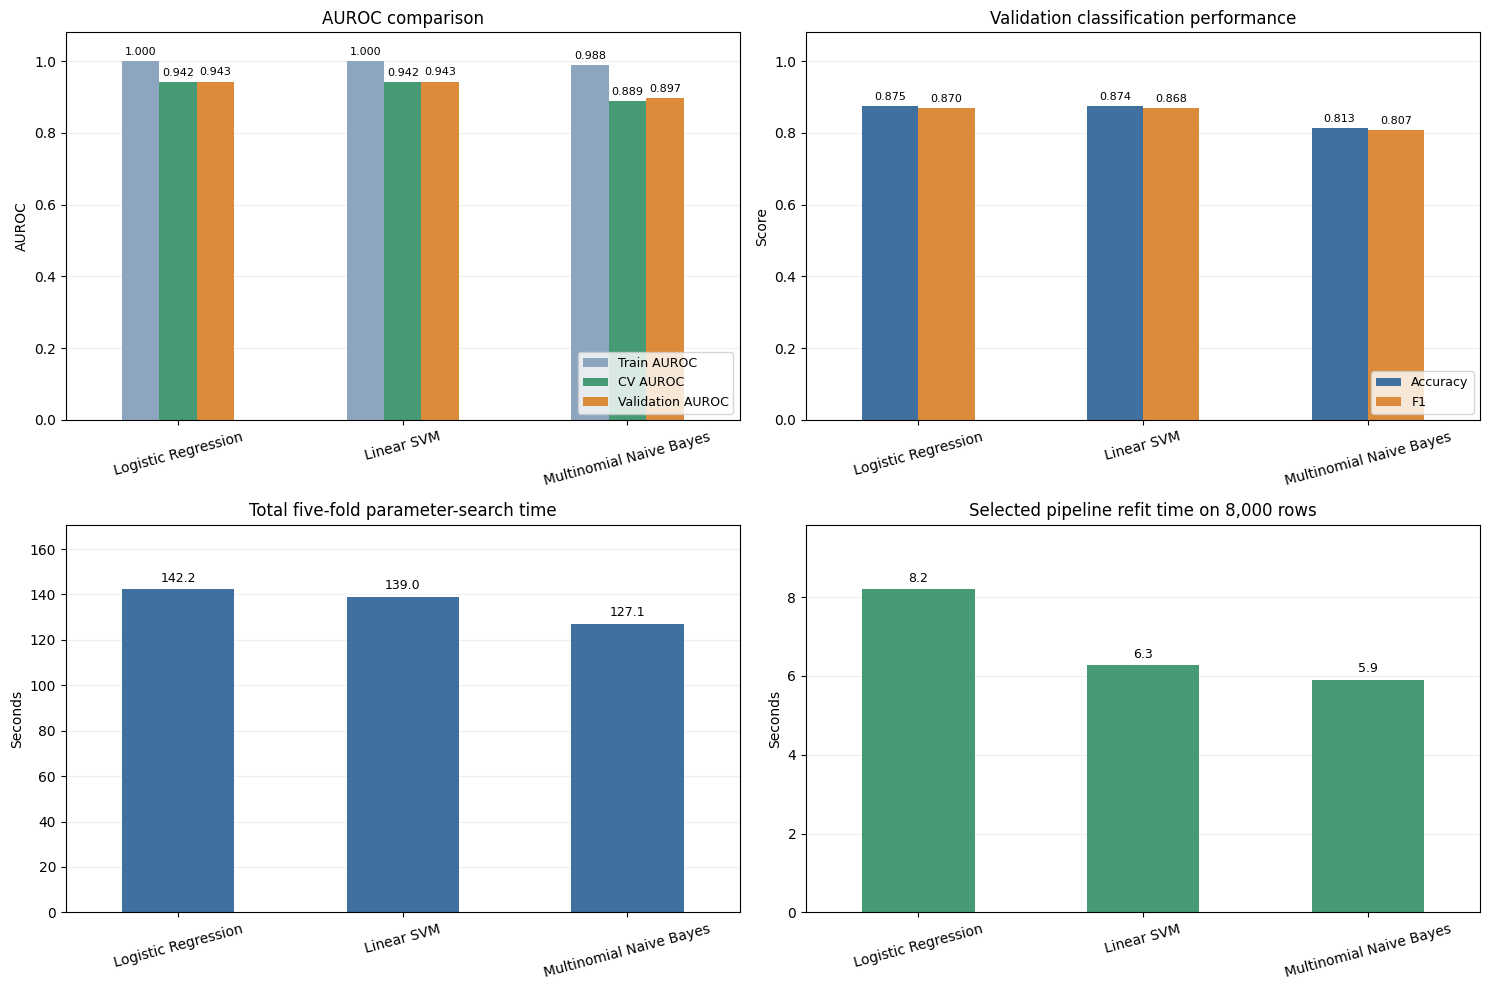

Search time includes all CV fits and the final refit.
Refit time includes TF-IDF and classifier fitting on 8,000 rows.
Prediction time includes TF-IDF transformation.
CV AUROC averages models trained on 6,400 rows per fold.


In [17]:
def evaluate_candidate(model, texts, labels):
    """Evaluate classifiers using either AI probabilities or SVM scores."""
    labels = np.asarray(labels)
    classes = np.asarray(model.classes_)

    assert np.array_equal(classes, [0, 1])
    assert set(np.unique(labels).tolist()) == {0, 1}

    start = perf_counter()

    if hasattr(model, "predict_proba"):
        ai_column = int(np.flatnonzero(classes == 1)[0])
        scores = model.predict_proba(texts)[:, ai_column]
        threshold = DECISION_THRESHOLD
        score_type = "AI probability"
    else:
        # For binary LinearSVC, positive scores indicate class 1.
        scores = model.decision_function(texts)
        threshold = 0.0
        score_type = "Decision score"

    predictions = (scores >= threshold).astype(int)
    prediction_seconds = perf_counter() - start

    assert len(scores) == len(labels)
    assert np.isfinite(scores).all()

    # AUROC uses continuous scores rather than thresholded predictions.
    metrics = {
        "AUROC": roc_auc_score(labels, scores),
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "Recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "F1": f1_score(
            labels, predictions, zero_division=0
        ),
        "Prediction seconds": prediction_seconds,
        "Score type": score_type,
        "Threshold": threshold,
    }

    return metrics, scores, predictions


comparison_rows = []
validation_outputs = {}

for name, search in searches.items():
    model = search.best_estimator_

    train_metrics, _, _ = evaluate_candidate(
        model, X_train, y_train
    )
    val_metrics, scores, predictions = evaluate_candidate(
        model, X_val, y_val
    )

    # Reuse these outputs for the selected-model diagnostic plots.
    validation_outputs[name] = {
        "metrics": val_metrics,
        "scores": scores,
        "predictions": predictions,
    }

    comparison_rows.append({
        "Model": name,
        "Train AUROC": train_metrics["AUROC"],
        "Validation AUROC": val_metrics["AUROC"],
        "AUROC gap": train_metrics["AUROC"] - val_metrics["AUROC"],
        "Validation accuracy": val_metrics["Accuracy"],
        "Validation precision": val_metrics["Precision"],
        "Validation recall": val_metrics["Recall"],
        "Validation F1": val_metrics["F1"],
        "Validation prediction seconds": val_metrics["Prediction seconds"],
        "Score type": val_metrics["Score type"],
        "Threshold": val_metrics["Threshold"],
    })

    # SVM decision scores are not probabilities.
    pd.DataFrame({
        "id": val_split["id"].to_numpy(),
        "label": np.asarray(y_val),
        "score": scores,
        "score_type": val_metrics["Score type"],
        "pred_label": predictions,
    }).to_csv(
        COMPARISON_DIR
        / f"{MODEL_SPECS[name]['file_tag']}_validation_predictions.csv",
        index=False,
    )

comparison_results = (
    cv_summary.merge(
        pd.DataFrame(comparison_rows),
        on="Model",
        validate="one_to_one",
    )
    .sort_values("CV AUROC", ascending=False, kind="stable")
    .reset_index(drop=True)
)

display(comparison_results[[
    "Model", "CV AUROC", "CV AUROC std",
    "Train AUROC", "Validation AUROC", "AUROC gap",
]].round(4))

display(comparison_results[[
    "Model", "Validation accuracy", "Validation precision",
    "Validation recall", "Validation F1",
]].round(4))

display(comparison_results[[
    "Model", "Search seconds", "Refit seconds",
    "Validation prediction seconds",
]].round(3))

comparison_results.to_csv(
    COMPARISON_DIR / "comparison_results.csv",
    index=False,
)

# Compare predictive performance and computational cost.
plot_results = comparison_results.set_index("Model")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

plot_results[[
    "Train AUROC", "CV AUROC", "Validation AUROC",
]].plot.bar(
    ax=axes[0, 0],
    color=["#8BA6BE", "#469A74", "#DB8B39"],
    rot=15,
)
axes[0, 0].set(
    title="AUROC comparison",
    xlabel="",
    ylabel="AUROC",
    ylim=(0, 1.08),
)
axes[0, 0].legend(fontsize=9, loc="lower right")

plot_results[[
    "Validation accuracy", "Validation F1",
]].plot.bar(
    ax=axes[0, 1],
    color=["#4070A0", "#DB8B39"],
    rot=15,
)
axes[0, 1].set(
    title="Validation classification performance",
    xlabel="",
    ylabel="Score",
    ylim=(0, 1.08),
)
axes[0, 1].legend(
    ["Accuracy", "F1"], fontsize=9, loc="lower right"
)

plot_results["Search seconds"].plot.bar(
    ax=axes[1, 0], color="#4070A0", rot=15,
)
axes[1, 0].set(
    title="Total five-fold parameter-search time",
    xlabel="",
    ylabel="Seconds",
)

plot_results["Refit seconds"].plot.bar(
    ax=axes[1, 1], color="#469A74", rot=15,
)
axes[1, 1].set(
    title="Selected pipeline refit time on 8,000 rows",
    xlabel="",
    ylabel="Seconds",
)

for ax in axes.ravel():
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

for ax in axes[0]:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3, fontsize=8)

for ax in axes[1]:
    ax.margins(y=0.2)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=9)

fig.tight_layout()
fig.savefig(
    COMPARISON_DIR / "model_performance_and_runtime.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Search time includes all CV fits and the final refit.")
print("Refit time includes TF-IDF and classifier fitting on 8,000 rows.")
print("Prediction time includes TF-IDF transformation.")
print("CV AUROC averages models trained on 6,400 rows per fold.")

### 4.5 Select the Best Model Configuration


Selected model: Logistic Regression
Best parameters: {'classifier__C': 10.0}
CV AUROC: 0.9419
Training AUROC: 1.0000
Validation AUROC: 0.9430
AUROC gap: 0.0570


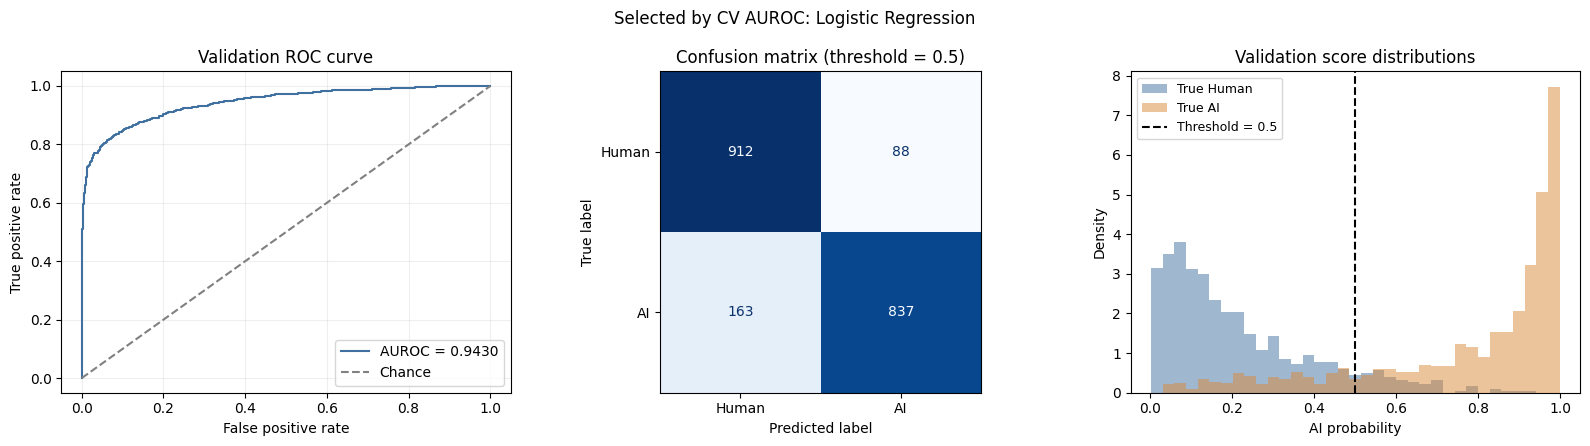


Results saved to: /content/drive/MyDrive/human_or_ai/outputs/model_comparison_5fold_5values


In [18]:
# Select by training-set CV AUROC, not held-out validation performance.
best_model_name = cv_summary.iloc[0]["Model"]
best_search = searches[best_model_name]
best_model = best_search.best_estimator_

selected_result = comparison_results.loc[
    comparison_results["Model"].eq(best_model_name)
].iloc[0]

selected_output = validation_outputs[best_model_name]
selected_metrics = selected_output["metrics"]
selected_scores = selected_output["scores"]
selected_predictions = selected_output["predictions"]

true_labels = np.asarray(y_val)
score_type = selected_metrics["Score type"]
threshold = selected_metrics["Threshold"]

print("Selected model:", best_model_name)
print("Best parameters:", best_search.best_params_)
print(f"CV AUROC: {selected_result['CV AUROC']:.4f}")
print(f"Training AUROC: {selected_result['Train AUROC']:.4f}")
print(f"Validation AUROC: {selected_result['Validation AUROC']:.4f}")
print(f"AUROC gap: {selected_result['AUROC gap']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# ROC measures ranking quality across decision thresholds.
fpr, tpr, _ = roc_curve(true_labels, selected_scores)
axes[0].plot(
    fpr, tpr,
    color="#4070A0",
    label=f"AUROC = {selected_metrics['AUROC']:.4f}",
)
axes[0].plot(
    [0, 1], [0, 1],
    "--", color="gray", label="Chance",
)
axes[0].set(
    title="Validation ROC curve",
    xlabel="False positive rate",
    ylabel="True positive rate",
)
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.2)

# Rows represent true labels; columns represent predicted labels.
cm = confusion_matrix(
    true_labels, selected_predictions, labels=[0, 1]
)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Human", "AI"],
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format="d",
)
axes[1].set_title(f"Confusion matrix (threshold = {threshold:g})")

# Shared bins make the two score distributions directly comparable.
bins = np.histogram_bin_edges(selected_scores, bins=35)

for label, name, color in [
    (0, "True Human", "#4070A0"),
    (1, "True AI", "#DB8B39"),
]:
    axes[2].hist(
        selected_scores[true_labels == label],
        bins=bins,
        density=True,
        alpha=0.5,
        color=color,
        label=name,
    )

axes[2].axvline(
    threshold,
    color="black",
    linestyle="--",
    label=f"Threshold = {threshold:g}",
)
axes[2].set(
    title="Validation score distributions",
    xlabel=score_type,
    ylabel="Density",
)
axes[2].legend(fontsize=9)

fig.suptitle(f"Selected by CV AUROC: {best_model_name}")
fig.tight_layout()
fig.savefig(
    COMPARISON_DIR / "selected_model_diagnostics.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# Preserve the fitted pipeline and experiment settings.
joblib.dump(
    best_model,
    COMPARISON_DIR / "best_model.joblib",
)

selection_metadata = {
    "selected_model": best_model_name,
    "selection_rule": "Highest mean training-set CV AUROC",
    "best_parameters": best_search.best_params_,
    "cv_folds": CV_FOLDS,
    "seed": SEED,
    "training_rows": len(X_train),
    "validation_rows": len(X_val),
    "cv_auroc": float(selected_result["CV AUROC"]),
    "cv_auroc_std": float(selected_result["CV AUROC std"]),
    "training_auroc": float(selected_result["Train AUROC"]),
    "validation_auroc": float(selected_result["Validation AUROC"]),
    "score_type": score_type,
    "classification_threshold": float(threshold),
    "tfidf_config": COMPARISON_TFIDF_CONFIG,
    "searched_parameters": {
        name: spec["param_grid"]
        for name, spec in MODEL_SPECS.items()
    },
    "split_metadata": json.loads(SPLIT_META_PATH.read_text()),
    "versions": VERSIONS,
}

(COMPARISON_DIR / "best_model_metadata.json").write_text(
    json.dumps(selection_metadata, indent=2),
    encoding="utf-8",
)

print(f"\nResults saved to: {COMPARISON_DIR.resolve()}")

if not hasattr(best_model, "predict_proba"):
    print(
        "The selected SVM produces decision scores, not probabilities. "
        "Probability calibration is needed before a probability submission."
    )

## 5. Effect of Training Data Size


### 5.1 Define the Controlled Experiment


In [19]:
import json
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone

SIZE_DIR = Path(OUTPUT_DIR) / "training_size_experiment"
SIZE_DIR.mkdir(parents=True, exist_ok=True)

SIZE_VALUES = [500, 1000, 2000, 5000, 8000]

size_train_df = train_split.reset_index(drop=True).copy()
size_val_df = val_split.reset_index(drop=True).copy()

assert len(size_train_df) == 8000 and len(size_val_df) == 2000
assert size_train_df["id"].is_unique and size_val_df["id"].is_unique
assert set(size_train_df["id"]).isdisjoint(size_val_df["id"])
assert size_train_df["label"].value_counts().to_dict() == {
    0: 4000, 1: 4000
}

# Keep hyperparameters, but remove fitted vocabulary and coefficients.
size_model_template = clone(best_model)

size_metadata = {
    "model": best_model_name,
    "selected_parameters": best_search.best_params_,
    "training_sizes": SIZE_VALUES,
    "sampling_seed": SEED,
    "sampling_method": (
        "Nested stratified subsets, preserving original row order"
    ),
    "validation_rows": len(size_val_df),
    "selection_scope": (
        "Configuration selected using the 8000-row training "
        "partition in Section 4"
    ),
    "tfidf_parameters": (
        size_model_template.named_steps["tfidf"].get_params()
    ),
    "classifier_parameters": (
        size_model_template.named_steps["classifier"].get_params()
    ),
    "split_metadata": json.loads(SPLIT_META_PATH.read_text()),
    "versions": VERSIONS,
}

(SIZE_DIR / "experiment_metadata.json").write_text(
    json.dumps(size_metadata, indent=2, default=str),
    encoding="utf-8",
)

print("Fixed model:", best_model_name)
print("Fixed selected parameters:", best_search.best_params_)
print("Training sizes:", SIZE_VALUES)
print("The same 2,000 validation rows are used throughout.")
print("Five fresh pipeline fits; no additional hyperparameter search.")

Fixed model: Logistic Regression
Fixed selected parameters: {'classifier__C': 10.0}
Training sizes: [500, 1000, 2000, 5000, 8000]
The same 2,000 validation rows are used throughout.
Five fresh pipeline fits; no additional hyperparameter search.


### 5.2 Construct Training Subsets (Stratified Sampling)


In [20]:
rng = np.random.default_rng(SEED)
size_labels = size_train_df["label"].to_numpy()

# Shuffle each class once to construct nested training subsets.
class_order = {
    label: rng.permutation(np.flatnonzero(size_labels == label))
    for label in [0, 1]
}

size_subset_indices = {}
subset_rows = []
assignment_frames = []
previous_indices = set()

for n in SIZE_VALUES:
    indices = np.sort(np.concatenate([
        class_order[0][:n // 2],
        class_order[1][:n // 2],
    ]))

    subset = size_train_df.iloc[indices]

    assert len(indices) == n and len(np.unique(indices)) == n
    assert previous_indices.issubset(set(indices))
    assert subset["label"].value_counts().to_dict() == {
        0: n // 2, 1: n // 2
    }

    size_subset_indices[n] = indices
    previous_indices = set(indices)

    subset_rows.append({
        "Training rows": n,
        "Human": int(subset["label"].eq(0).sum()),
        "AI": int(subset["label"].eq(1).sum()),
        "AI share (%)": 100 * subset["label"].mean(),
    })

    assignment_frames.append(
        subset[["id", "label"]].assign(training_rows=n)
    )

# Preserve the original training order at the full-data endpoint.
assert np.array_equal(
    size_subset_indices[8000], np.arange(8000)
)

subset_summary = pd.DataFrame(subset_rows)
display(subset_summary)

subset_summary.to_csv(
    SIZE_DIR / "subset_summary.csv",
    index=False,
)

pd.concat(assignment_frames, ignore_index=True).to_csv(
    SIZE_DIR / "subset_assignments.csv",
    index=False,
)

,Training rows,Human,AI,AI share (%)
0,500,250,250,50.0
1,1000,500,500,50.0
2,2000,1000,1000,50.0
3,5000,2500,2500,50.0
4,8000,4000,4000,50.0


### 5.3 Train and Evaluate Each Subset


In [21]:
learning_rows = []
size_prediction_frames = []

for n in SIZE_VALUES:
    subset = size_train_df.iloc[size_subset_indices[n]]
    size_model = clone(size_model_template)

    # Learn TF-IDF and classifier parameters from this subset only.
    start = perf_counter()
    size_model.fit(subset["text"], subset["label"])
    fit_seconds = perf_counter() - start

    # Section 4.4 supports both probabilities and SVM decision scores.
    train_metrics, _, _ = evaluate_candidate(
        size_model,
        subset["text"],
        subset["label"],
    )

    val_metrics, val_scores, val_predictions = evaluate_candidate(
        size_model,
        size_val_df["text"],
        size_val_df["label"],
    )

    learning_rows.append({
        "Training rows": n,
        "Training AUROC": train_metrics["AUROC"],
        "Validation AUROC": val_metrics["AUROC"],
        "AUROC gap": (
            train_metrics["AUROC"] - val_metrics["AUROC"]
        ),
        "Training seconds": fit_seconds,
        "Features": len(
            size_model.named_steps["tfidf"].vocabulary_
        ),
    })

    size_prediction_frames.append(pd.DataFrame({
        "training_rows": n,
        "id": size_val_df["id"].to_numpy(),
        "label": size_val_df["label"].to_numpy(),
        "score": val_scores,
        "score_type": val_metrics["Score type"],
        "threshold": val_metrics["Threshold"],
        "pred_label": val_predictions,
    }))

    print(
        f"n={n:>5,} | "
        f"Train AUROC={train_metrics['AUROC']:.4f} | "
        f"Validation AUROC={val_metrics['AUROC']:.4f} | "
        f"Fit time={fit_seconds:.2f}s",
        flush=True,
    )

learning_results = (
    pd.DataFrame(learning_rows)
    .sort_values("Training rows")
    .reset_index(drop=True)
)

learning_results.to_csv(
    SIZE_DIR / "learning_curve_results.csv",
    index=False,
)

pd.concat(size_prediction_frames, ignore_index=True).to_csv(
    SIZE_DIR / "validation_predictions.csv",
    index=False,
)

display(learning_results.round(4))

print(
    "Training time includes TF-IDF and classifier fitting, "
    "excluding evaluation."
)

n=  500 | Train AUROC=1.0000 | Validation AUROC=0.8513 | Fit time=0.46s
n=1,000 | Train AUROC=1.0000 | Validation AUROC=0.8890 | Fit time=0.92s
n=2,000 | Train AUROC=1.0000 | Validation AUROC=0.9207 | Fit time=3.21s
n=5,000 | Train AUROC=1.0000 | Validation AUROC=0.9366 | Fit time=4.25s
n=8,000 | Train AUROC=1.0000 | Validation AUROC=0.9430 | Fit time=7.96s


,Training rows,Training AUROC,Validation AUROC,AUROC gap,Training seconds,Features
0,500,1.0,0.8513,0.1487,0.4580,14360
1,1000,1.0,0.8890,0.1110,0.9162,27223
2,2000,1.0,0.9207,0.0793,3.2057,50000
3,5000,1.0,0.9366,0.0634,4.2454,50000
4,8000,1.0,0.9430,0.0570,7.9641,50000


Training time includes TF-IDF and classifier fitting, excluding evaluation.


### 5.4 Plot Training and Validation Learning Curves


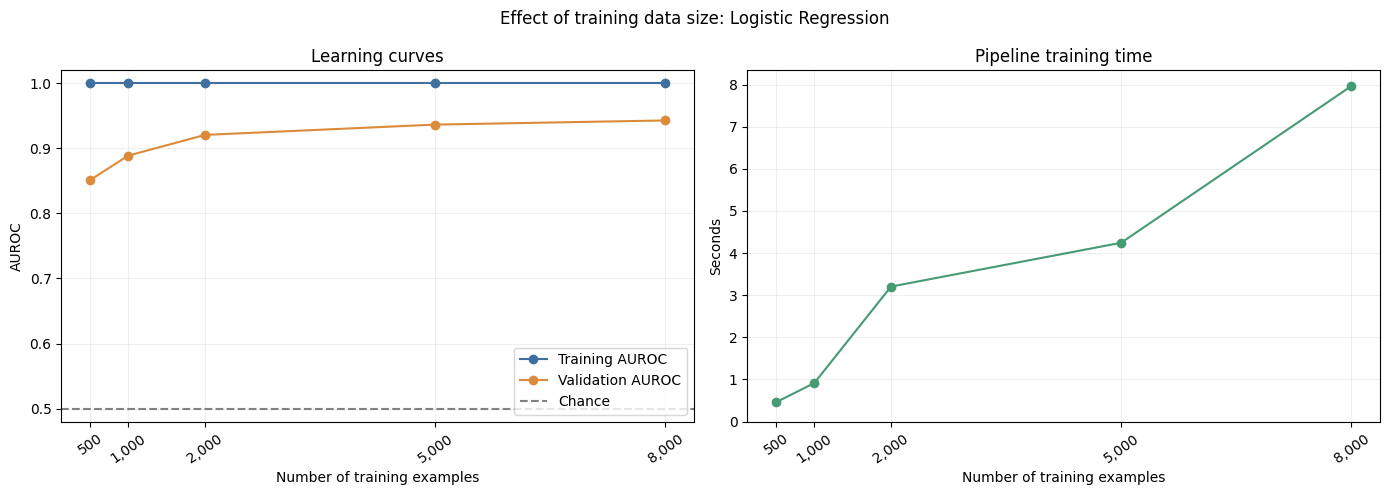

In [22]:
x = learning_results["Training rows"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    x,
    learning_results["Training AUROC"].to_numpy(),
    marker="o",
    color="#4070A0",
    label="Training AUROC",
)

axes[0].plot(
    x,
    learning_results["Validation AUROC"].to_numpy(),
    marker="o",
    color="#DB8B39",
    label="Validation AUROC",
)

axes[0].axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="Chance",
)

minimum_auc = learning_results[
    ["Training AUROC", "Validation AUROC"]
].min().min()

axes[0].set(
    title="Learning curves",
    xlabel="Number of training examples",
    ylabel="AUROC",
    ylim=(max(0, min(0.48, minimum_auc - 0.02)), 1.02),
)
axes[0].legend(loc="lower right")

axes[1].plot(
    x,
    learning_results["Training seconds"].to_numpy(),
    marker="o",
    color="#469A74",
)

axes[1].set(
    title="Pipeline training time",
    xlabel="Number of training examples",
    ylabel="Seconds",
)
axes[1].set_ylim(bottom=0)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{n:,}" for n in x],
        rotation=35,
    )
    ax.grid(alpha=0.2)

fig.suptitle(
    f"Effect of training data size: {best_model_name}"
)
fig.tight_layout()

fig.savefig(
    SIZE_DIR / "learning_curves_and_runtime.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### 5.5 Interpret Overfitting, Underfitting, and Data Efficiency


In [23]:
size_analysis = learning_results.copy()

size_analysis["Added rows"] = (
    size_analysis["Training rows"].diff()
)

size_analysis["Validation AUROC change"] = (
    size_analysis["Validation AUROC"].diff()
)

# Normalize gains because the increases in training size are unequal.
size_analysis["AUROC gain per 1,000 added rows"] = (
    1000
    * size_analysis["Validation AUROC change"]
    / size_analysis["Added rows"]
)

display(size_analysis[[
    "Training rows",
    "Training AUROC",
    "Validation AUROC",
    "AUROC gap",
    "Added rows",
    "Validation AUROC change",
    "AUROC gain per 1,000 added rows",
]].round(4))

size_analysis.to_csv(
    SIZE_DIR / "data_efficiency_analysis.csv",
    index=False,
)

first = learning_results.iloc[0]
last = learning_results.iloc[-1]
previous = learning_results.iloc[-2]

overall_gain = (
    last["Validation AUROC"] - first["Validation AUROC"]
)
last_gain = (
    last["Validation AUROC"] - previous["Validation AUROC"]
)

summary = (
    f"Model: {best_model_name}\n"
    f"Validation AUROC, 500 to 8,000 rows: "
    f"{first['Validation AUROC']:.4f} -> "
    f"{last['Validation AUROC']:.4f}\n"
    f"Overall validation AUROC change: {overall_gain:+.4f}\n"
    f"Validation AUROC change, 5,000 to 8,000 rows: "
    f"{last_gain:+.4f}\n"
    f"Training-validation gap, 500 to 8,000 rows: "
    f"{first['AUROC gap']:.4f} -> "
    f"{last['AUROC gap']:.4f}\n\n"

    # "Interpretation guide:\n"
    # "- A high training score with a lower validation score "
    # "is consistent with overfitting.\n"
    # "- Low scores on both splits may suggest underfitting "
    # "or limited text features.\n"
    # "- Rising validation AUROC suggests additional labeled "
    # "data helps this configuration.\n"
    # "- A flattening validation curve suggests diminishing "
    # "returns over the tested range.\n\n"

    # "Scope: these results use one nested sampling sequence "
    # "and one fixed validation set. Small differences may "
    # "reflect sampling variation. The configuration was selected "
    # "using all 8,000 training rows in Section 4, so the "
    # "small-subset scores do not represent an entire "
    # "model-selection process performed with only that subset. "
    # "The curves alone do not establish the cause of a "
    # "performance gap."
)

print(summary)

(SIZE_DIR / "interpretation_notes.txt").write_text(
    summary,
    encoding="utf-8",
)

print("\nResults saved to:", SIZE_DIR.resolve())

,Training rows,Training AUROC,Validation AUROC,AUROC gap,Added rows,Validation AUROC change,"AUROC gain per 1,000 added rows"
0,500,1.0,0.8513,0.1487,NaN,NaN,NaN
1,1000,1.0,0.8890,0.1110,500.0,0.0377,0.0753
2,2000,1.0,0.9207,0.0793,1000.0,0.0318,0.0318
3,5000,1.0,0.9366,0.0634,3000.0,0.0158,0.0053
4,8000,1.0,0.9430,0.0570,3000.0,0.0064,0.0021


Model: Logistic Regression
Validation AUROC, 500 to 8,000 rows: 0.8513 -> 0.9430
Overall validation AUROC change: +0.0917
Validation AUROC change, 5,000 to 8,000 rows: +0.0064
Training-validation gap, 500 to 8,000 rows: 0.1487 -> 0.0570



Results saved to: /content/drive/MyDrive/human_or_ai/outputs/training_size_experiment


## 6. Learning from Unlabeled Data


### 6.1 Define the Semi-Supervised Learning Method


In [24]:
import json
import hashlib
import joblib
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import roc_curve

SSL_DIR = Path(OUTPUT_DIR) / "semi_supervised_single_round"
SSL_DIR.mkdir(parents=True, exist_ok=True)

PSEUDO_THRESHOLD = 0.95
assert 0.5 < PSEUDO_THRESHOLD < 1.0

ssl_train = (
    train_split[["id", "text", "label"]]
    .reset_index(drop=True).copy()
)
ssl_val = (
    val_split[["id", "text", "label"]]
    .reset_index(drop=True).copy()
)
ssl_unlabeled = (
    unlabeled_df[["id", "text"]]
    .reset_index(drop=True).copy()
)

assert (
    len(ssl_train), len(ssl_val), len(ssl_unlabeled)
) == (8000, 2000, 3000)

for frame in [ssl_train, ssl_val, ssl_unlabeled]:
    assert not frame.isna().any().any()
    assert frame["id"].is_unique
    assert frame["text"].map(
        lambda text: isinstance(text, str)
    ).all()
    assert frame["text"].str.strip().ne("").all()

# Reuse Section 2's normalization only for overlap checks.
for left, right in [
    (ssl_train, ssl_val),
    (ssl_train, ssl_unlabeled),
    (ssl_val, ssl_unlabeled),
]:
    assert set(left["id"]).isdisjoint(right["id"])
    assert set(
        normalize_for_audit(left["text"])
    ).isdisjoint(
        normalize_for_audit(right["text"])
    ), "Review overlapping texts before this experiment."

ssl_template = clone(best_model)

if not hasattr(ssl_template, "predict_proba"):
    raise TypeError(
        "This experiment requires predict_proba, as provided "
        "by the selected logistic regression."
    )


def save_ssl_figure(fig, stem):
    """Save both a preview image and a vector PDF."""
    fig.tight_layout()
    fig.savefig(
        SSL_DIR / f"{stem}.png",
        dpi=200,
        bbox_inches="tight",
    )
    fig.savefig(
        SSL_DIR / f"{stem}.pdf",
        bbox_inches="tight",
    )


print("Model:", best_model_name)
print("Fixed parameters:", best_search.best_params_)
print("Pseudo-label confidence threshold:", PSEUDO_THRESHOLD)
print(
    "One round; equal sample weights; "
    "no additional parameter search."
)

Model: Logistic Regression
Fixed parameters: {'classifier__C': 10.0}
Pseudo-label confidence threshold: 0.95
One round; equal sample weights; no additional parameter search.


### 6.2 Generate and Select Pseudo-Labels


,Group,Rows
0,Selected Human,236
1,Selected AI,403
2,Not selected,2361


Selected: 639/3,000 (21.3%)


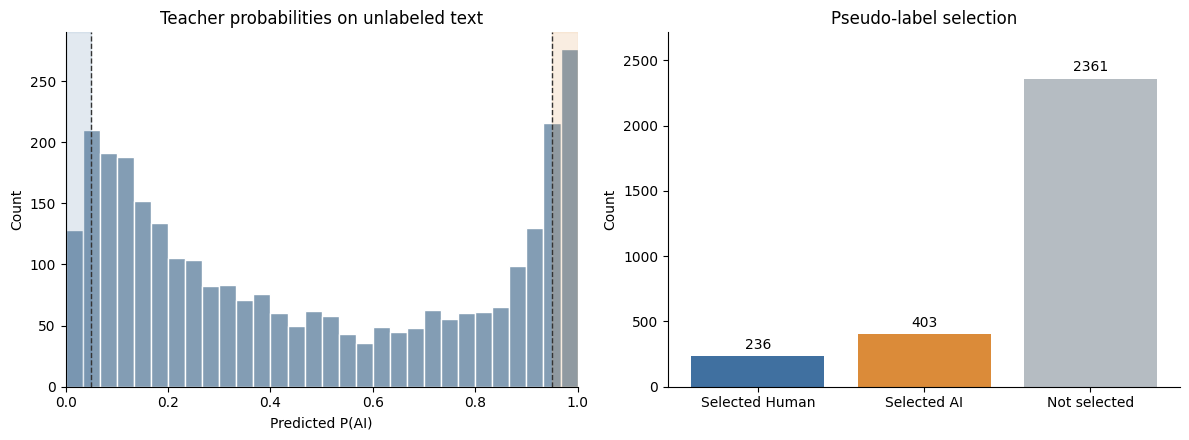

In [25]:
# Refit a clean teacher on the 8,000 true labels only.
ssl_teacher = clone(ssl_template)

start = perf_counter()
ssl_teacher.fit(ssl_train["text"], ssl_train["label"])
teacher_fit_seconds = perf_counter() - start

assert np.array_equal(ssl_teacher.classes_, [0, 1])

start = perf_counter()

ai_column = int(
    np.flatnonzero(ssl_teacher.classes_ == 1)[0]
)
unlabeled_prob = ssl_teacher.predict_proba(
    ssl_unlabeled["text"]
)[:, ai_column]

assert np.isfinite(unlabeled_prob).all()
assert (
    (unlabeled_prob >= 0) & (unlabeled_prob <= 1)
).all()

pseudo_labels = (unlabeled_prob >= 0.5).astype(int)
pseudo_confidence = np.maximum(
    unlabeled_prob, 1 - unlabeled_prob
)
selected_mask = pseudo_confidence >= PSEUDO_THRESHOLD

pseudo_seconds = perf_counter() - start

pseudo_audit = pd.DataFrame({
    "id": ssl_unlabeled["id"].to_numpy(),
    "prob_ai": unlabeled_prob,
    "pseudo_label": pseudo_labels,
    "confidence": pseudo_confidence,
    "selected": selected_mask,
})
pseudo_audit.to_csv(
    SSL_DIR / "pseudo_label_audit.csv",
    index=False,
)

n_pseudo = int(selected_mask.sum())
n_human = int(
    (selected_mask & (pseudo_labels == 0)).sum()
)
n_ai = int(
    (selected_mask & (pseudo_labels == 1)).sum()
)

selection_summary = pd.DataFrame({
    "Group": [
        "Selected Human",
        "Selected AI",
        "Not selected",
    ],
    "Rows": [
        n_human,
        n_ai,
        len(ssl_unlabeled) - n_pseudo,
    ],
})

display(selection_summary)
selection_summary.to_csv(
    SSL_DIR / "selection_summary.csv",
    index=False,
)

print(
    f"Selected: {n_pseudo:,}/{len(ssl_unlabeled):,} "
    f"({100 * selected_mask.mean():.1f}%)"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(
    unlabeled_prob,
    bins=np.linspace(0, 1, 31),
    color="#839DB4",
    edgecolor="white",
)

for cutoff in [
    1 - PSEUDO_THRESHOLD,
    PSEUDO_THRESHOLD,
]:
    axes[0].axvline(
        cutoff,
        color="#333333",
        linestyle="--",
        linewidth=1,
    )

axes[0].axvspan(
    0, 1 - PSEUDO_THRESHOLD,
    color="#4070A0", alpha=0.15,
)
axes[0].axvspan(
    PSEUDO_THRESHOLD, 1,
    color="#DB8B39", alpha=0.15,
)
axes[0].set(
    title="Teacher probabilities on unlabeled text",
    xlabel="Predicted P(AI)",
    ylabel="Count",
    xlim=(0, 1),
)

bars = axes[1].bar(
    selection_summary["Group"].tolist(),
    selection_summary["Rows"].to_numpy(),
    color=["#4070A0", "#DB8B39", "#B5BCC2"],
)
axes[1].bar_label(bars, padding=3)
axes[1].margins(y=0.15)
axes[1].set(
    title="Pseudo-label selection",
    ylabel="Count",
)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

save_ssl_figure(fig, "pseudo_label_selection")
plt.show()

### 6.3 Retrain with Labeled and Pseudo-Labeled Data


In [26]:
pseudo_train = ssl_unlabeled.loc[
    selected_mask, ["id", "text"]
].copy()
pseudo_train["label"] = pseudo_labels[selected_mask]

ssl_augmented = pd.concat([
    ssl_train.assign(label_source="true"),
    pseudo_train.assign(label_source="pseudo"),
], ignore_index=True)

assert len(ssl_augmented) == 8000 + n_pseudo
assert ssl_augmented["id"].is_unique
assert set(ssl_augmented["id"]).isdisjoint(ssl_val["id"])

ssl_augmented[[
    "id", "label", "label_source"
]].to_csv(
    SSL_DIR / "training_assignments.csv",
    index=False,
)

# Relearn vocabulary, IDF, and classifier on augmented data.
ssl_student = clone(ssl_template)

start = perf_counter()
ssl_student.fit(
    ssl_augmented["text"],
    ssl_augmented["label"],
)
student_fit_seconds = perf_counter() - start

joblib.dump(
    ssl_teacher,
    SSL_DIR / "supervised_model.joblib",
)
joblib.dump(
    ssl_student,
    SSL_DIR / "pseudo_label_model.joblib",
)

print(f"Student training rows: {len(ssl_augmented):,}")
print(
    f"Student pipeline fit time: "
    f"{student_fit_seconds:.2f}s"
)

if n_pseudo == 0:
    print(
        "No samples passed the threshold; "
        "the student is a supervised refit."
    )

Student training rows: 8,639
Student pipeline fit time: 14.36s


### 6.4 Compare Against the Supervised Baseline


,Method,True labeled rows,Pseudo-labeled rows,Training AUROC,Validation AUROC,Validation F1,Fit seconds,Workflow seconds
0,Supervised only,8000,0,1.0,0.942963,0.8696,8.18,8.18
1,With pseudo-labels,8000,639,1.0,0.943046,0.8693,14.36,23.63


Validation AUROC change: +0.000083
Workflow time includes fitting and pseudo-label generation, excluding evaluation and file saving.


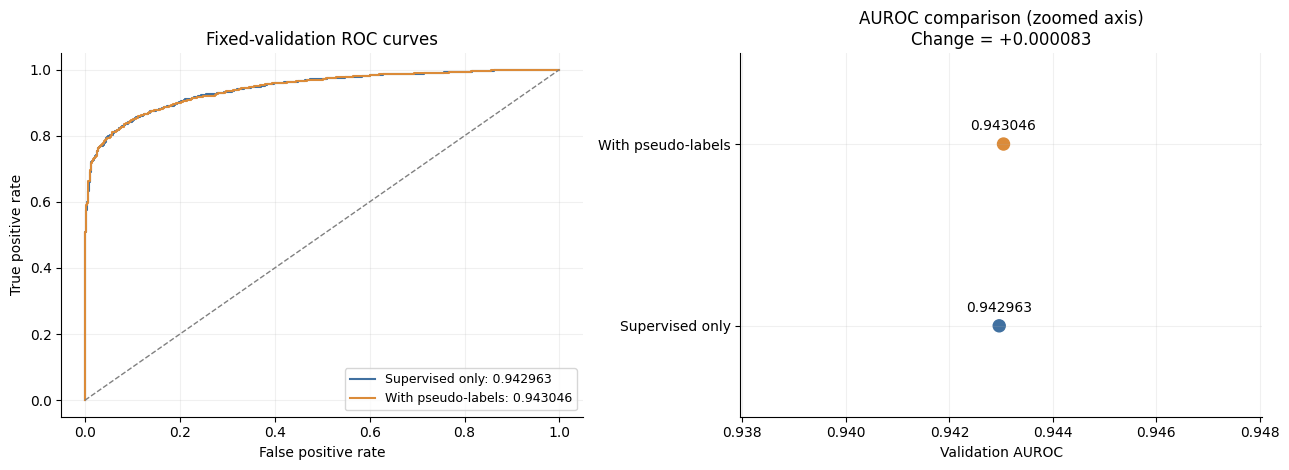

In [27]:
ssl_rows = []
ssl_predictions = {}

ssl_specs = [
    (
        "Supervised only",
        ssl_teacher,
        0,
        teacher_fit_seconds,
        teacher_fit_seconds,
    ),
    (
        "With pseudo-labels",
        ssl_student,
        n_pseudo,
        student_fit_seconds,
        teacher_fit_seconds + pseudo_seconds + student_fit_seconds,
    ),
]

for method, model, added_rows, fit_time, workflow_time in ssl_specs:
    # Use the same TRUE training labels for both models.
    train_metrics, _, _ = evaluate_candidate(
        model,
        ssl_train["text"],
        ssl_train["label"],
    )
    val_metrics, scores, predictions = evaluate_candidate(
        model,
        ssl_val["text"],
        ssl_val["label"],
    )

    ssl_predictions[method] = scores

    ssl_rows.append({
        "Method": method,
        "True labeled rows": len(ssl_train),
        "Pseudo-labeled rows": added_rows,
        "Training AUROC": train_metrics["AUROC"],
        "Validation AUROC": val_metrics["AUROC"],
        "Validation F1": val_metrics["F1"],
        "Fit seconds": fit_time,
        "Workflow seconds": workflow_time,
    })

    file_tag = (
        "supervised"
        if method == "Supervised only"
        else "pseudo_label"
    )

    pd.DataFrame({
        "id": ssl_val["id"].to_numpy(),
        "label": ssl_val["label"].to_numpy(),
        "prob_ai": scores,
        "pred_label": predictions,
    }).to_csv(
        SSL_DIR / f"{file_tag}_validation_predictions.csv",
        index=False,
    )

ssl_results = pd.DataFrame(ssl_rows)
ssl_results.to_csv(
    SSL_DIR / "comparison_results.csv",
    index=False,
)

display(ssl_results.round({
    "Training AUROC": 6,
    "Validation AUROC": 6,
    "Validation F1": 4,
    "Fit seconds": 2,
    "Workflow seconds": 2,
}))

ssl_auc_before, ssl_auc_after = (
    ssl_results["Validation AUROC"].to_numpy()
)
ssl_auc_change = float(ssl_auc_after - ssl_auc_before)

print(f"Validation AUROC change: {ssl_auc_change:+.6f}")
print(
    "Workflow time includes fitting and pseudo-label generation, "
    "excluding evaluation and file saving."
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colors = ["#4070A0", "#DB8B39"]

for color, method in zip(colors, ssl_results["Method"]):
    fpr, tpr, _ = roc_curve(
        ssl_val["label"],
        ssl_predictions[method],
    )

    auc = float(ssl_results.loc[
        ssl_results["Method"].eq(method),
        "Validation AUROC",
    ].iloc[0])

    axes[0].plot(
        fpr, tpr,
        color=color,
        label=f"{method}: {auc:.6f}",
    )

axes[0].plot(
    [0, 1], [0, 1],
    "--", color="gray", linewidth=1,
)
axes[0].set(
    title="Fixed-validation ROC curves",
    xlabel="False positive rate",
    ylabel="True positive rate",
)
axes[0].legend(loc="lower right", fontsize=9)

# Explicitly label the zoomed axis when showing small differences.
auc_values = ssl_results["Validation AUROC"].to_numpy()

axes[1].scatter(
    auc_values, [0, 1],
    c=colors, s=75,
)

for i, value in enumerate(auc_values):
    axes[1].annotate(
        f"{value:.6f}",
        (value, i),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
    )

axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(
    ssl_results["Method"].tolist()
)

padding = max(
    0.005,
    float(np.ptp(auc_values)) * 0.8,
)

axes[1].set(
    xlim=(
        max(0, auc_values.min() - padding),
        min(1, auc_values.max() + padding),
    ),
    ylim=(-0.5, 1.5),
    xlabel="Validation AUROC",
    title=(
        "AUROC comparison (zoomed axis)\n"
        f"Change = {ssl_auc_change:+.6f}"
    ),
)

for ax in axes:
    ax.grid(alpha=0.18)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

save_ssl_figure(fig, "validation_comparison")
plt.show()

### 6.5 Discuss Pseudo-Label Noise and Validation Leakage Prevention


In [29]:
if n_pseudo == 0:
    outcome = (
        "No pseudo-labels were selected; this run did not "
        "add unlabeled training data."
    )
elif ssl_auc_change > 0:
    outcome = (
        "Pseudo-labeling improved AUROC on this fixed "
        "validation set."
    )
elif ssl_auc_change < 0:
    outcome = (
        "Pseudo-labeling reduced AUROC on this fixed "
        "validation set."
    )
else:
    outcome = "Pseudo-labeling left validation AUROC unchanged."

ssl_summary = (
    f"Selected {n_pseudo:,} of {len(ssl_unlabeled):,} "
    f"unlabeled examples using confidence >= "
    f"{PSEUDO_THRESHOLD:.2f}: "
    f"{n_human:,} pseudo-Human and {n_ai:,} pseudo-AI.\n"
    f"Validation AUROC: {ssl_auc_before:.6f} -> "
    f"{ssl_auc_after:.6f} "
    f"(change {ssl_auc_change:+.6f}). {outcome}\n\n"

    # "Pseudo-label accuracy cannot be measured because "
    # "the unlabeled examples have no ground-truth labels. "
    # "The teacher's probabilities are not explicitly calibrated, "
    # "so confidence 0.95 does not guarantee 95% correctness. "
    # "Incorrect predictions may reinforce existing errors; "
    # "selected samples may also be unrepresentative. "

    # "Both classifiers and TF-IDF use the same hyperparameter "
    # "settings, but the student learns its vocabulary and IDF "
    # "from the augmented data. This comparison measures the "
    # "combined effect of pseudo-labeling and refitting the "
    # "representation. "

    # "Validation texts and labels are excluded from fitting, "
    # "and the threshold was fixed before evaluation. "
    # "One run on one validation split does not establish "
    # "statistical significance or guarantee an improvement "
    # "on the hidden test set."
)

print(ssl_summary)

(SSL_DIR / "experiment_summary.txt").write_text(
    ssl_summary,
    encoding="utf-8",
)

ssl_metadata = {
    "method": "Single-round confidence-based pseudo-labeling",
    "model": best_model_name,
    "selected_parameters": best_search.best_params_,
    "pseudo_threshold": PSEUDO_THRESHOLD,
    "classification_threshold": DECISION_THRESHOLD,
    "sample_weight": 1.0,
    "seed": SEED,
    "selected_human": n_human,
    "selected_ai": n_ai,
    "validation_auroc_change": ssl_auc_change,
    "tfidf_parameters": (
        ssl_template.named_steps["tfidf"].get_params()
    ),
    "classifier_parameters": (
        ssl_template.named_steps["classifier"].get_params()
    ),
    "split_metadata": json.loads(
        SPLIT_META_PATH.read_text()
    ),
    "unlabeled_sha256": hashlib.sha256(
        Path(UNLABELED_PATH).read_bytes()
    ).hexdigest(),
    "versions": VERSIONS,
}

(SSL_DIR / "experiment_metadata.json").write_text(
    json.dumps(ssl_metadata, indent=2, default=str),
    encoding="utf-8",
)

print("\nResults saved to:", SSL_DIR.resolve())

Selected 639 of 3,000 unlabeled examples using confidence >= 0.95: 236 pseudo-Human and 403 pseudo-AI.
Validation AUROC: 0.942963 -> 0.943046 (change +0.000083). Pseudo-labeling improved AUROC on this fixed validation set.



Results saved to: /content/drive/MyDrive/human_or_ai/outputs/semi_supervised_single_round


## 7. Generalization and Error Analysis


### 7.1 Analyze the Training–Validation Performance Gap


In [30]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

ERROR_DIR = Path(OUTPUT_DIR) / "generalization_error_analysis"
ERROR_DIR.mkdir(parents=True, exist_ok=True)

analysis_train = (
    train_split[["id", "text", "label"]]
    .reset_index(drop=True).copy()
)
analysis_val = (
    val_split[["id", "text", "label"]]
    .reset_index(drop=True).copy()
)

assert len(analysis_train) == 8000
assert len(analysis_val) == 2000
assert set(analysis_train["id"]).isdisjoint(analysis_val["id"])

# Refit the selected configuration on true training labels only.
analysis_model = clone(best_model)
analysis_model.fit(
    analysis_train["text"],
    analysis_train["label"],
)

if not hasattr(analysis_model, "predict_proba"):
    raise TypeError(
        "This analysis requires a probability classifier, "
        "such as the selected logistic regression."
    )

analysis_train_metrics, _, _ = evaluate_candidate(
    analysis_model,
    analysis_train["text"],
    analysis_train["label"],
)
analysis_val_metrics, analysis_prob, _ = evaluate_candidate(
    analysis_model,
    analysis_val["text"],
    analysis_val["label"],
)

analysis_val["prob_ai"] = analysis_prob
analysis_val["words"] = analysis_val["text"].str.count(r"\S+")

gap_results = pd.DataFrame([
    {
        "Split": "Training",
        "Rows": len(analysis_train),
        "AUROC": analysis_train_metrics["AUROC"],
    },
    {
        "Split": "Validation",
        "Rows": len(analysis_val),
        "AUROC": analysis_val_metrics["AUROC"],
    },
])

analysis_auc_gap = (
    analysis_train_metrics["AUROC"]
    - analysis_val_metrics["AUROC"]
)

display(gap_results.round(6))
print(f"Training-validation AUROC gap: {analysis_auc_gap:.6f}")

gap_results.to_csv(
    ERROR_DIR / "generalization_gap.csv",
    index=False,
)


def save_analysis_figure(fig, name):
    fig.tight_layout()
    fig.savefig(
        ERROR_DIR / f"{name}.png",
        dpi=200,
        bbox_inches="tight",
    )
    fig.savefig(
        ERROR_DIR / f"{name}.pdf",
        bbox_inches="tight",
    )

,Split,Rows,AUROC
0,Training,8000,1.000000
1,Validation,2000,0.942963


Training-validation AUROC gap: 0.057037


### 7.2 Evaluate Performance Across Text Length Groups


,Length group,Rows,Human,AI,Validation AUROC,CI low,CI high
0,Short (<=150),413,156,257,0.9075,0.8789,0.9337
1,Medium (151-250),1056,619,437,0.9510,0.9382,0.9633
2,Long (>250),531,225,306,0.9575,0.9421,0.9724


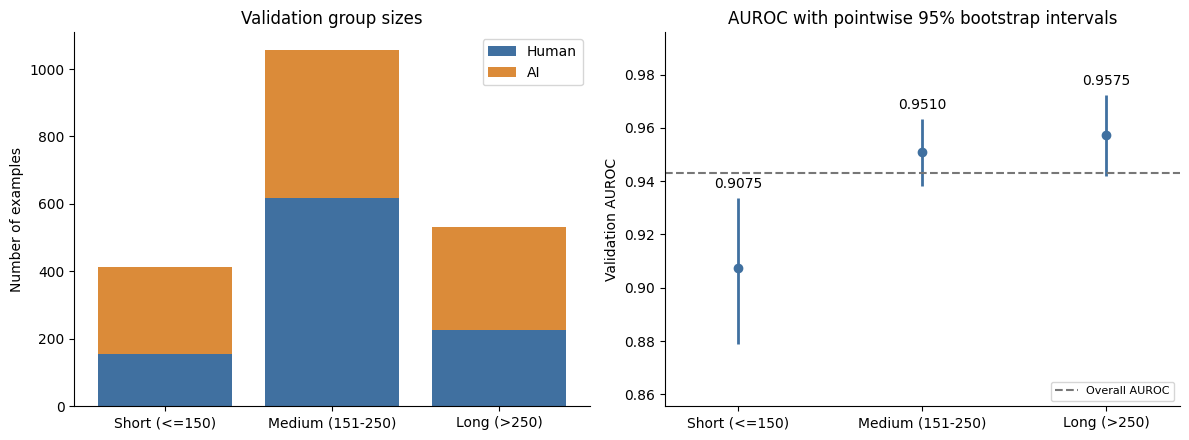

Intervals reflect resampling within this validation set, not model-training variability.
Group differences alone do not establish that text length causes the performance difference.


In [31]:
LENGTH_GROUPS = [
    "Short (<=150)",
    "Medium (151-250)",
    "Long (>250)",
]

analysis_val["length_group"] = pd.cut(
    analysis_val["words"],
    bins=[-np.inf, 150, 250, np.inf],
    labels=LENGTH_GROUPS,
)

BOOTSTRAP_REPEATS = 1000


def stratified_auc_interval(labels, scores, seed):
    """Pointwise percentile interval conditional on the fitted model."""
    labels = np.asarray(labels)
    scores = np.asarray(scores)

    if len(np.unique(labels)) < 2:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)
    class_indices = [
        np.flatnonzero(labels == label)
        for label in [0, 1]
    ]

    bootstrap_auc = np.empty(BOOTSTRAP_REPEATS)

    for i in range(BOOTSTRAP_REPEATS):
        indices = np.concatenate([
            rng.choice(idx, size=len(idx), replace=True)
            for idx in class_indices
        ])
        bootstrap_auc[i] = roc_auc_score(
            labels[indices],
            scores[indices],
        )

    low, high = np.quantile(
        bootstrap_auc, [0.025, 0.975]
    )

    return roc_auc_score(labels, scores), low, high


length_rows = []

for i, group in enumerate(LENGTH_GROUPS):
    subset = analysis_val.loc[
        analysis_val["length_group"].eq(group)
    ]

    auc, low, high = stratified_auc_interval(
        subset["label"],
        subset["prob_ai"],
        SEED + i,
    )

    length_rows.append({
        "Length group": group,
        "Rows": len(subset),
        "Human": int(subset["label"].eq(0).sum()),
        "AI": int(subset["label"].eq(1).sum()),
        "Validation AUROC": auc,
        "CI low": low,
        "CI high": high,
    })

length_results = pd.DataFrame(length_rows)

assert length_results["Rows"].sum() == len(analysis_val)

display(length_results.round(4))
length_results.to_csv(
    ERROR_DIR / "length_group_results.csv",
    index=False,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(LENGTH_GROUPS))

axes[0].bar(
    x,
    length_results["Human"].to_numpy(),
    label="Human",
    color="#4070A0",
)
axes[0].bar(
    x,
    length_results["AI"].to_numpy(),
    bottom=length_results["Human"].to_numpy(),
    label="AI",
    color="#DB8B39",
)
axes[0].set(
    title="Validation group sizes",
    ylabel="Number of examples",
)
axes[0].legend()

for i, row in length_results.iterrows():
    if pd.notna(row["Validation AUROC"]):
        axes[1].vlines(
            i,
            row["CI low"],
            row["CI high"],
            color="#4070A0",
            linewidth=2,
        )
        axes[1].scatter(
            i,
            row["Validation AUROC"],
            color="#4070A0",
            zorder=3,
        )
        axes[1].annotate(
            f"{row['Validation AUROC']:.4f}",
            (i, row["CI high"]),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
        )

axes[1].axhline(
    analysis_val_metrics["AUROC"],
    color="#777777",
    linestyle="--",
    label="Overall AUROC",
)
axes[1].set(
    title="AUROC with pointwise 95% bootstrap intervals",
    ylabel="Validation AUROC",
)
axes[1].margins(x=0.2, y=0.25)
axes[1].legend(loc="lower right", fontsize=8)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(LENGTH_GROUPS)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

save_analysis_figure(fig, "length_group_analysis")
plt.show()

print(
    "Intervals reflect resampling within this validation set, "
    "not model-training variability."
)
print(
    "Group differences alone do not establish that text length "
    "causes the performance difference."
)

### 7.3 Define the Classification Threshold


,Threshold,TN,FP,FN,TP,False positive rate,False negative rate
0,0.5,912,88,163,837,0.088,0.163


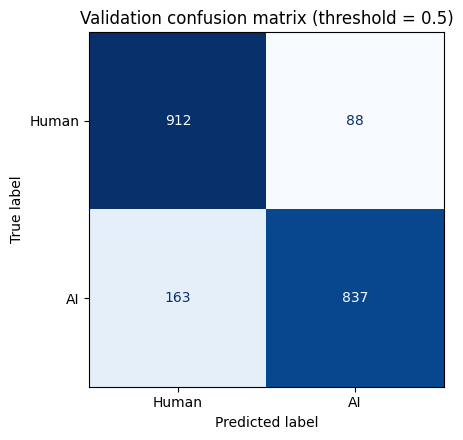

Review policy: five highest-P(AI) false positives and five lowest-P(AI) false negatives.
These are confident mistakes, not a representative random sample of all errors.


In [32]:
ERROR_THRESHOLD = 0.5

analysis_val["pred_label"] = (
    analysis_val["prob_ai"] >= ERROR_THRESHOLD
).astype(int)

analysis_val["error_type"] = np.select(
    [
        analysis_val["label"].eq(0)
        & analysis_val["pred_label"].eq(1),

        analysis_val["label"].eq(1)
        & analysis_val["pred_label"].eq(0),
    ],
    ["FP", "FN"],
    default="Correct",
)

cm = confusion_matrix(
    analysis_val["label"],
    analysis_val["pred_label"],
    labels=[0, 1],
)

tn, fp, fn, tp = cm.ravel()

threshold_results = pd.DataFrame([{
    "Threshold": ERROR_THRESHOLD,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
    "False positive rate": fp / (tn + fp),
    "False negative rate": fn / (tp + fn),
}])

display(threshold_results.round(4))

threshold_results.to_csv(
    ERROR_DIR / "threshold_results.csv",
    index=False,
)
analysis_val.drop(columns="text").to_csv(
    ERROR_DIR / "validation_diagnostics.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(5, 4.5))

ConfusionMatrixDisplay(
    cm,
    display_labels=["Human", "AI"],
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d",
)

ax.set_title(
    f"Validation confusion matrix "
    f"(threshold = {ERROR_THRESHOLD:g})"
)

save_analysis_figure(fig, "validation_confusion_matrix")
plt.show()

print(
    "Review policy: five highest-P(AI) false positives "
    "and five lowest-P(AI) false negatives."
)
print(
    "These are confident mistakes, not a representative "
    "random sample of all errors."
)

### 7.4 Analyze Five False Positives


In [34]:
def sample_error_cases(error_type, n=5, seed=SEED):
    """Randomly sample actual errors from the fixed validation set."""
    if error_type == "FP":
        mask = (
            analysis_val["label"].eq(0)
            & analysis_val["prob_ai"].ge(ERROR_THRESHOLD)
        )
    elif error_type == "FN":
        mask = (
            analysis_val["label"].eq(1)
            & analysis_val["prob_ai"].lt(ERROR_THRESHOLD)
        )
    else:
        raise ValueError("error_type must be 'FP' or 'FN'.")

    # Stable ordering makes sampling reproducible.
    candidates = analysis_val.loc[mask].sort_values("id")

    if len(candidates) < n:
        raise ValueError(
            f"Only {len(candidates)} {error_type} cases are "
            f"available; cannot sample {n} unique cases."
        )

    sampled = candidates.sample(
        n=n,
        replace=False,
        random_state=seed,
    ).copy()

    sampled["error_type"] = error_type
    sampled["pred_label"] = (
        sampled["prob_ai"] >= ERROR_THRESHOLD
    ).astype(int)

    sampled = sampled[[
        "id",
        "error_type",
        "label",
        "pred_label",
        "prob_ai",
        "words",
        "text",
    ]].reset_index(drop=True)

    print(
        f"{error_type}: sampled {n} of "
        f"{len(candidates)} cases; seed={seed}"
    )

    display(
        sampled.drop(columns="text").round(6)
    )

    # Show the actual text for manual inspection.
    for case in sampled.itertuples(index=False):
        print(
            f"\nID: {case.id} | {case.error_type} | "
            f"True label: {case.label} | "
            f"Predicted label: {case.pred_label} | "
            f"P(AI): {case.prob_ai:.6f}"
        )
        print(f"Words: {case.words}")
        print("Text:")
        print(case.text)

    sampled.to_csv(
        ERROR_DIR / f"{error_type.lower()}_review.csv",
        index=False,
    )

    return sampled


fp_review = sample_error_cases(
    error_type="FP",
    n=5,
    seed=SEED,
)

FP: sampled 5 of 88 cases; seed=42


,id,error_type,label,pred_label,prob_ai,words
0,8367,FP,0,1,0.595675,142
1,11,FP,0,1,0.561703,207
2,3470,FP,0,1,0.749639,160
3,2635,FP,0,1,0.662049,152
4,1890,FP,0,1,0.544933,192



ID: 8367 | FP | True label: 0 | Predicted label: 1 | P(AI): 0.595675
Words: 142
Text:
Cathodoluminescence (CL) imaging spectroscopy is an important technique to
understand resonant behavior of optical nanoantennas. We report high-resolution
CL spectroscopy of triangular gold nanoantennas designed with near-vacuum
effective index and very small metal-substrate interface. This design helped in
addressing issues related to background luminescence and shifting of dipole
modes beyond visible spectrum. Spatial and spectral investigations of various
plasmonic modes are reported. Out-of-plane dipole modes excited with vertically
illuminated electron beam showed high-contrast tip illumination in panchromatic
imaging. By tilting the nanostructures during fabrication, in-plane dipole
modes of antennas were excited. Finite-difference time-domain simulations for
electron and optical excitations of different modes showed excellent agreement
with experimental results. Our approach of efficiently exc

### 7.5 Analyze Five False Negatives


In [35]:
fn_review = sample_error_cases(
    error_type="FN",
    n=5,
    seed=SEED,
)

error_review = pd.concat(
    [fp_review, fn_review],
    ignore_index=True,
)

assert len(error_review) == 10
assert error_review["id"].is_unique

error_review.to_csv(
    ERROR_DIR / "ten_error_cases.csv",
    index=False,
)

FN: sampled 5 of 163 cases; seed=42


,id,error_type,label,pred_label,prob_ai,words
0,8249,FN,1,0,0.227720,100
1,6733,FN,1,0,0.305195,163
2,7971,FN,1,0,0.388126,193
3,3169,FN,1,0,0.358061,296
4,5265,FN,1,0,0.420630,76



ID: 8249 | FN | True label: 1 | Predicted label: 0 | P(AI): 0.227720
Words: 100
Text:
The Jedi Order was brought down by its own ignorance.

The Jedi were so focused on the Light Side of the Force that they neglected the Dark Side. They did not understand the power of the Dark Side, and so they were unprepared for the rise of the Sith.

The Sith were able to take advantage of the Jedi's ignorance, and they used the Dark Side to destroy the Jedi Order.

The Jedi's ignorance was the real downfall of the order. If the Jedi had been more open-minded, they might have been able to prevent the rise of the Sith.

ID: 6733 | FN | True label: 1 | Predicted label: 0 | P(AI): 0.305195
Words: 163
Text:
Middlesbrough have suffered a major blow to their promotion hopes after it was confirmed that midfielder George Morrison will be out for the rest of the season.

The 24-year-old suffered a fractured ankle in the 1-0 defeat to Reading on Saturday and will undergo surgery in the coming days.

Morrison

### 7.6 Identify Recurring Failure Patterns and Potential Remedies


In [36]:
length_error_rows = []

for group in LENGTH_GROUPS:
    subset = analysis_val.loc[
        analysis_val["length_group"].eq(group)
    ]

    human_mask = subset["label"].eq(0)
    ai_mask = subset["label"].eq(1)
    predicted_ai = subset["prob_ai"].ge(ERROR_THRESHOLD)

    human_count = int(human_mask.sum())
    ai_count = int(ai_mask.sum())

    fp_count = int((human_mask & predicted_ai).sum())
    fn_count = int((ai_mask & ~predicted_ai).sum())

    length_error_rows.append({
        "Length group": group,
        "Rows": len(subset),
        "Human": human_count,
        "AI": ai_count,
        "False positives": fp_count,
        "False negatives": fn_count,
        "False positive rate": (
            fp_count / human_count
            if human_count else np.nan
        ),
        "False negative rate": (
            fn_count / ai_count
            if ai_count else np.nan
        ),
    })

length_error_results = pd.DataFrame(length_error_rows)

display(length_error_results.round(4))

length_error_results.to_csv(
    ERROR_DIR / "length_group_error_rates.csv",
    index=False,
)

sampling_metadata = {
    "selection_method": (
        "Random sampling without replacement within "
        "each error type, after sorting by ID"
    ),
    "seed": SEED,
    "threshold": ERROR_THRESHOLD,
    "false_positive_ids": fp_review["id"].tolist(),
    "false_negative_ids": fn_review["id"].tolist(),
}

(ERROR_DIR / "error_sampling_metadata.json").write_text(
    json.dumps(sampling_metadata, indent=2),
    encoding="utf-8",
)

print(
    "Total false positives:",
    int(length_error_results["False positives"].sum()),
)
print(
    "Total false negatives:",
    int(length_error_results["False negatives"].sum()),
)
print("Results saved to:", ERROR_DIR.resolve())

,Length group,Rows,Human,AI,False positives,False negatives,False positive rate,False negative rate
0,Short (<=150),413,156,257,22,51,0.1410,0.1984
1,Medium (151-250),1056,619,437,59,59,0.0953,0.1350
2,Long (>250),531,225,306,7,53,0.0311,0.1732


Total false positives: 88
Total false negatives: 163
Results saved to: /content/drive/MyDrive/human_or_ai/outputs/generalization_error_analysis


## 8. Open-Ended Improvement Experiment


### 8.1 State the Hypothesis and Motivation


### 8.2 Describe the Proposed Improvement


### 8.3 Define the Baseline and Controlled Variables


### 8.4 Compare Validation Performance and Runtime


### 8.5 Discuss Findings, Limitations, and Next Steps


## 9. Final Model Training and Kaggle Submission


### 9.1 Confirm the Final Modeling Approach


### 9.2 Retrain on All Labeled Data


### 9.3 Generate Test-Set Probabilities


### 9.4 Validate and Export the Submission File


### 9.5 Record Kaggle Public and Private Scores


## 10. Results Export, Reproducibility, and Documentation


### 10.1 Summarize the Final Pipeline and Results


### 10.2 Export Experiment Tables and Figures


### 10.3 Document Dependencies, Random Seeds, and Execution Instructions


### 10.4 Link the GitHub Pull Request and Meaningful Development Commits


### 10.5 Document Team Contributions and AI Assistance


### 10.6 Complete the Final Submission Checklist
